# La connettività dei cieli: traffico aereo e low-cost in Europa

**Corso:** Principi e modelli della percezione · **Corso di laurea:** Informatica per la Comunicazione Digitale

**Dati.** Programmazione delle rotte europee raccolta con web scraping ad **agosto 2025** (dataset Kaggle *European Airports & Air Routes*): non è un'istantanea del 2026 né un dato ufficiale (vedi par. 3.1) e validata con le tabelle ufficiali Eurostat (par. 3.2).

**Domanda di ricerca.** Com'è fatta oggi la rete aerea europea? Quali aeroporti fanno da hub, quanto pesano le compagnie low-cost e come si è evoluta la rete negli ultimi anni, con la crescita delle rotte regionali rispetto ai grandi scali storici?

**Il notebook procede così:**
1. caricamento e pulizia del dataset
2. filtro sull'Europa e classificazione delle rotte (low-cost / tradizionale / mista)
3. data wrangling: grafo degli aeroporti, hub, matrice origine-destinazione
4. visualizzazioni (mappe interattive e grafici)
5. conclusioni e limiti dell'analisi

## 1. Setup

In [2]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
from IPython.display import Image, display

DATA, IMG, OUT = Path("data"), Path("images"), Path("outputs")
IMG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

# Palette fissa: ogni tipo di rotta ha SEMPRE lo stesso colore in tutti i grafici
COL = {"Low-cost": "#F28E2B", "Tradizionale": "#4E79A7", "Mista": "#9C9C9C"}
ORDER = ["Low-cost", "Mista", "Tradizionale"]
INK = "#1f2933"

def show(fig, name, w=1400, h=800, width_px=950):
    """Salva la versione interattiva (HTML) e statica (PNG) e mostra il PNG nel notebook.
    Il PNG permette di vedere i grafici anche su GitHub, dove il JavaScript di Plotly non gira."""
    fig.write_html(OUT / f"{name}.html", include_plotlyjs="cdn")
    fig.write_image(IMG / f"{name}.png", width=w, height=h, scale=2)
    # nel notebook mostro una versione a risoluzione normale (file più leggero); il PNG ad alta risoluzione resta in images/
    display(Image(data=fig.to_image(format="png", width=w, height=h, scale=1), width=width_px))

def labels(S):
    """Nome città per le etichette; se due aeroporti hanno la stessa città aggiunge il codice IATA (es. London LHR)."""
    nm = S.citta.str.replace(" de Mallorca", "")
    dup = nm.duplicated(keep=False)
    return np.where(dup, nm + " " + S.index, nm)

def label_pos(S):
    """Posizione dell'etichetta: se due aeroporti hanno la stessa città, una va sopra e l'altra sotto per non sovrapporle."""
    nm = S.citta.str.replace(" de Mallorca", "")
    seen, pos = {}, []
    for name, d in zip(nm, nm.duplicated(keep=False)):
        seen[name] = seen.get(name, 0) + 1
        pos.append("top center" if (not d or seen[name] % 2) else "bottom center")
    return pos

def base_layout(fig, title, subtitle=None):
    t = f"<b>{title}</b>" + (f"<br><span style='font-size:14px;color:#52606d'>{subtitle}</span>" if subtitle else "")
    fig.update_layout(template="plotly_white", title=dict(text=t, x=0.01, xanchor="left"),
                      font=dict(family="Arial", size=15, color=INK), margin=dict(l=70, r=30, t=95, b=60),
                      legend=dict(orientation="h", y=1.02, x=1, xanchor="right", yanchor="bottom"))
    return fig

## 2. Caricamento dei dati

Il file `europe_air_routes.csv` contiene **una riga per ogni rotta diretta** (A→B) con: frequenza settimanale, data del primo volo, prezzo, coordinate degli aeroporti e, nella colonna `airlineroutes`, l'elenco (in formato testo) delle compagnie che operano la rotta.

In [3]:
raw = pd.read_csv(DATA / "europe_air_routes.csv")
print(f"Righe: {len(raw):,}  |  Colonne: {raw.shape[1]}")
raw[["iata_from", "iata_to", "price", "flights_per_week", "first_flight", "last_flight",
     "departure_country", "arrival_airport_country"]].head()

Righe: 18,111  |  Colonne: 33


,iata_from,iata_to,price,flights_per_week,first_flight,last_flight,departure_country,arrival_airport_country
0,TZL,DTM,70,4,5/24/2025,10/31/2026,Bosnia and Herzegovina,Germany
1,TZL,FMM,30,4,11/4/2022,11/2/2026,Bosnia and Herzegovina,Germany
2,TZL,MLH,40,4,12/21/2024,11/1/2026,Bosnia and Herzegovina,Switzerland
3,TZL,BER,40,3,3/30/2026,10/15/2026,Bosnia and Herzegovina,Germany
4,TZL,MMX,90,3,12/13/2025,10/15/2026,Bosnia and Herzegovina,Sweden


### 2.1 Variabili e tipi
La tabella elenca le 33 colonne del file con tipo, valori mancanti e uso. Solo una parte serve all'analisi: le altre (giorni della settimana, durata, altitudini, codici ICAO) restano nel file ma non entrano nel clustering. I valori mancanti formali sono pochi (solo le coordinate di alcuni aeroporti di arrivo), ma **in diverse colonne l'informazione mancante è codificata con `0`** (data di primo volo, prezzo, frequenza): lo verifichiamo nel paragrafo 3.1.

In [4]:
# Variabili del file, tipo e ruolo nell'analisi
TIPO = {"id": "identificativo", "iata_from": "categorica (codice aeroporto)", "iata_to": "categorica (codice aeroporto)",
        "price": "numerica continua (€ stimati)", "flights_per_week": "numerica discreta", "common_duration": "numerica (minuti)",
        "flights_per_day": "categorica ordinale (testo)", "first_flight": "data (testo)", "last_flight": "data (testo)",
        "airlineroutes": "testo strutturato (lista di dizionari)"}
for i in range(1, 8): TIPO[f"day{i}"] = "categorica (yes / no / upcoming)"
USATE = {"iata_from", "iata_to", "price", "flights_per_week", "first_flight", "airlineroutes", "departure_city", "departure_country",
         "departure_latitude", "departure_longitude", "arrival_airport_city_name_en", "arrival_airport_country"}

def tipo_col(c, s):
    if c in TIPO: return TIPO[c]
    if "latitude" in c or "longitude" in c or "altitude" in c or c.endswith("no_routes"): return "numerica continua" if "itude" in c else "numerica discreta"
    return "categorica (testo)"

var_tab = pd.DataFrame({"dtype pandas": raw.dtypes.astype(str),
                        "tipo statistico": [tipo_col(c, raw[c]) for c in raw.columns],
                        "valori mancanti": raw.isna().sum(),
                        "esempio": [str(raw[c].iloc[0])[:28] for c in raw.columns],
                        "usata nell'analisi": ["sì" if c in USATE else "no" for c in raw.columns]})
print(f"{len(raw):,} righe (campioni) × {raw.shape[1]} variabili; usate nell'analisi: {len(USATE)}")
var_tab

18,111 righe (campioni) × 33 variabili; usate nell'analisi: 12


,dtype pandas,tipo statistico,valori mancanti,esempio,usata nell'analisi
id,int64,identificativo,0,46316,no
iata_from,str,categorica (codice aeroporto),0,TZL,sì
iata_to,str,categorica (codice aeroporto),0,DTM,sì
price,int64,numerica continua (€ stimati),0,70,sì
day1,str,categorica (yes / no / upcoming),0,no,no
day2,str,categorica (yes / no / upcoming),0,yes,no
day3,str,categorica (yes / no / upcoming),0,no,no
day4,str,categorica (yes / no / upcoming),0,yes,no
day5,str,categorica (yes / no / upcoming),0,no,no
day6,str,categorica (yes / no / upcoming),0,yes,no


## 3. Filtro sull'Europa

Il file contiene anche destinazioni intercontinentali (177 paesi di arrivo). Teniamo **solo le rotte con entrambi gli estremi in Europa**. Un aeroporto è considerato europeo se compare come partenza nel dataset (il file è costruito dagli aeroporti europei), escludendo i paesi transcontinentali (Kazakhstan, Armenia, Azerbaijan, Georgia). La Turchia e la Russia europea restano incluse.

In [5]:
NON_EUROPE = {"Kazakhstan", "Armenia", "Azerbaijan", "Georgia"}
eu_airports = set(raw.loc[~raw.departure_country.isin(NON_EUROPE), "iata_from"])

df = raw[raw.iata_from.isin(eu_airports) & raw.iata_to.isin(eu_airports)].copy()
print(f"Rotte dirette totali nel file : {len(raw):,}")
print(f"Rotte dirette intra-europee   : {len(df):,}  ({len(df)/len(raw):.0%})")
print(f"Aeroporti europei             : {len(eu_airports):,}")

Rotte dirette totali nel file : 18,111
Rotte dirette intra-europee   : 13,499  (75%)
Aeroporti europei             : 253


### 3.1 Provenienza e qualità dei dati
**Fonte.** Il file è il dataset Kaggle *European Airports & Air Routes* (V. Laputsky): le rotte sono state raccolte con web scraping del sito **FlightsFrom** per circa 260 grandi aeroporti europei (elenco AirMundo), le coordinate vengono da OpenFlights. Secondo la descrizione su Kaggle l'estrazione è del **11/8/2025**. Non è un dato ufficiale (non è Eurostat né Eurocontrol) e non è validato.

**Cosa descrive una riga.** Non un singolo volo, ma una **rotta con il suo orario programmato**: frequenza settimanale (`flights_per_week`), giorni operativi, data del primo e dell'ultimo volo di quella programmazione. Non ci sono passeggeri.

**A quale data si riferisce.** L'estrazione è del 2025, **non del 2026**: `first_flight` arriva fino a luglio 2026 perché il sito mostra anche rotte *annunciate*, e `last_flight` arriva fino a ottobre 2026 (fine stagione estiva) e aprile 2027. Qui sotto verifichiamo che la data dichiarata sia coerente con i dati.

In [6]:
EXTRACTION_DATE = pd.Timestamp("2025-08-11")   # dalla descrizione Kaggle ("11/8/2025", lettura giorno/mese); da cambiare qui se la si legge 8 novembre
first = pd.to_datetime(raw.first_flight, errors="coerce")
last = pd.to_datetime(raw.last_flight, errors="coerce")

print("DATE")
print(f"  last_flight: dal {last.min():%d/%m/%Y} al {last.max():%d/%m/%Y}; rotte con last_flight prima dell'estrazione: {(last < EXTRACTION_DATE).sum()}")
print(f"  rotte con last_flight prima dell'8/11/2025 (lettura alternativa): {(last < pd.Timestamp('2025-11-08')).sum()}  -> se l'estrazione fosse di novembre, queste sarebbero già concluse")
print(f"  first_flight: dal {first.min():%d/%m/%Y} al {first.max():%d/%m/%Y}; sconosciuto (0): {first.isna().sum():,} ({first.isna().mean():.0%}); dopo l'estrazione (annunciate): {(first > EXTRACTION_DATE).sum()}")
print(f"  picco del primo volo nel marzo 2018: {((first >= '2018-03-01') & (first < '2018-04-01')).sum()} rotte (avvio della raccolta dati, non un boom reale)")
print("\nVALORI A ZERO")
z = raw.flights_per_week == 0
print(f"  flights_per_week = 0: {z.sum()} righe, di cui con primo volo dopo l'estrazione: {(z & (first > EXTRACTION_DATE)).sum()}")
print(f"  price = 0: {(raw.price == 0).sum():,} righe ({(raw.price == 0).mean():.0%}); price massimo: {raw.price.max():,} €")
print("\nSIMMETRIA (A→B ha anche B→A?) tra aeroporti europei")
pairs = set(zip(df.iata_from, df.iata_to))
print(f"  {np.mean([(b, a) in pairs for a, b in pairs]):.1%} delle rotte dirette ha la rotta di ritorno nel file")
print("\nCOPERTURA")
print(f"  aeroporti di partenza nel file: {raw.iata_from.nunique()} (Kaggle dichiara circa 260 grandi aeroporti); aeroporti europei dopo il filtro: {len(eu_airports)}")

DATE
  last_flight: dal 15/09/2025 al 01/04/2030; rotte con last_flight prima dell'estrazione: 0
  rotte con last_flight prima dell'8/11/2025 (lettura alternativa): 251  -> se l'estrazione fosse di novembre, queste sarebbero già concluse
  first_flight: dal 16/12/2017 al 16/07/2026; sconosciuto (0): 3,016 (17%); dopo l'estrazione (annunciate): 753
  picco del primo volo nel marzo 2018: 2001 rotte (avvio della raccolta dati, non un boom reale)

VALORI A ZERO
  flights_per_week = 0: 488 righe, di cui con primo volo dopo l'estrazione: 386
  price = 0: 1,963 righe (11%); price massimo: 16,100 €

SIMMETRIA (A→B ha anche B→A?) tra aeroporti europei
  99.2% delle rotte dirette ha la rotta di ritorno nel file

COPERTURA
  aeroporti di partenza nel file: 258 (Kaggle dichiara circa 260 grandi aeroporti); aeroporti europei dopo il filtro: 253


**Cosa ricaviamo.**
- **Data.** Nessuna rotta ha `last_flight` precedente a metà settembre 2025: è coerente con un'estrazione di **agosto 2025** (con un'estrazione di novembre ci sarebbero circa 250 rotte già concluse). Il file è quindi una *fotografia della programmazione di agosto 2025*, che copre fino a ottobre 2026 (stagione estiva 2026) e in parte fino ad aprile 2027. Non è un'istantanea "2026".
- **Rotte annunciate.** Circa 750 righe hanno il primo volo dopo l'estrazione: sono rotte programmate, non ancora operative. Nelle analisi per anno di nascita (6.5, 6.6) le escludiamo.
- **Zeri = dato mancante.** Il prezzo è 0 in ~11% delle righe e la frequenza è 0 in 488 righe (386 con primo volo dopo l'estrazione, cioè rotte non ancora partite): per i voli settimanali sono quindi una **sottostima** per queste rotte, e il prezzo resta solo un'indicazione (campo "estimated price", non documentato).
- **Simmetria.** Tra aeroporti europei il 99% delle rotte ha anche il ritorno nel file: lo scraping è quasi completo. Uniamo comunque i due versi in collegamenti non orientati (5.1).
- **Copertura.** Sono solo i ~260 grandi aeroporti scelti dall'autore: i "regionali" di questa analisi sono scali medio-grandi, non piccoli aeroporti, e le destinazioni di ogni aeroporto sono contate solo verso gli altri aeroporti del campione.
- **Plausibilità.** Francoforte ha ~6.900 voli settimanali verso l'Europa (circa 1.000 al giorno in entrambi i versi), Stansted è quasi tutto low-cost, Las Palmas–Tenerife è la rotta più frequente: sono ordini di grandezza credibili. È solo un controllo qualitativo: la validazione vera, con i dati ufficiali Eurostat, è nel paragrafo 3.2.
- **Dimensione.** 18.111 righe sono più che sufficienti per descrivere la rete; per il clustering l'unità è però l'**aeroporto**: 253 campioni e 3 variabili sono pochi per gruppi stabili (lo mostra l'ARI 0,71 tra inizializzazioni). Più righe non aiuterebbero; servirebbero più aeroporti o più variabili (es. passeggeri).

### 3.2 Validazione con i dati ufficiali Eurostat
I controlli del paragrafo precedente dicono che i dati sono *coerenti*, non che siano *giusti*. Per verificarlo li confrontiamo con una fonte ufficiale: le tabelle Eurostat **`avia_par_*`** (voli e passeggeri per rotta, dichiarati dai paesi per i loro aeroporti principali). Le tabelle originali pesano circa 800 MB e non stanno nel repository: lo script `scripts/validazione_eurostat.py` le legge, abbina le rotte con il **codice ICAO** (presente in entrambe le fonti) e salva il risultato in `data/eurostat_validazione_rotte.csv`.

Confronto: `flights_per_week` del dataset (programmazione di agosto 2025) contro i **voli 2024 di Eurostat divisi per 52,3 settimane**. Usiamo la media annua e non agosto perché il dataset riporta una frequenza tipica e non il picco estivo (lo verifichiamo sotto).

Rotte europee del dataset con riscontro Eurostat: 8,527 su 13,499 (63%); quota dei voli settimanali: 87%
Rotte confrontabili (voli > 0 in entrambe le fonti): 8,520



Per rotta: correlazione di Spearman = 0.90 (con i voli di agosto 2024: 0.80)
Rapporto scraping / Eurostat: mediana 1.04, intervallo interquartile 0.82–1.31
Rotte entro ±30%: 57%  |  entro un fattore 2: 87%
Per aeroporto (144 aeroporti con almeno 20 rotte confrontabili): Spearman = 0.98; totale voli: scraping 103,317 contro Eurostat 98,152 a settimana


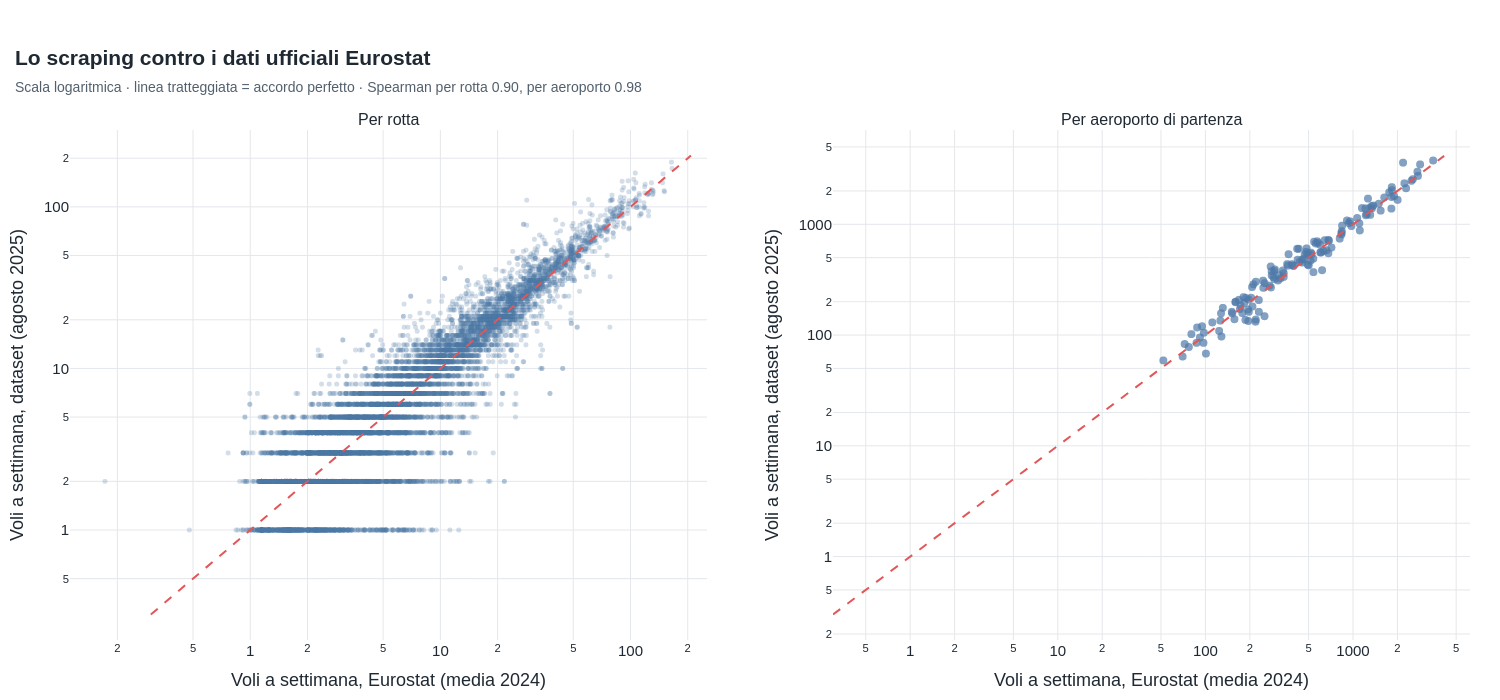

,scraping,eurostat,rotte,rapporto
iata_from,,,,
AMS,3767,3490.82,136,1.08
FRA,3473,2848.62,124,1.22
MAD,2734,2754.19,101,0.99
BCN,2983,2730.23,117,1.09
CDG,2553,2542.07,101,1.00
MUC,2470,2488.81,116,0.99
FCO,2116,2288.96,108,0.92
LHR,2343,2229.71,76,1.05
IST,3600,2183.45,98,1.65


In [7]:
val = pd.read_csv(DATA / "eurostat_validazione_rotte.csv")
v = val[(val.voli_eurostat_2024 > 0) & (val.voli_sett_scraping > 0)].copy()
v["voli_sett_eurostat"] = v.voli_eurostat_2024 / (366 / 7)                 # 2024 è bisestile
v["voli_sett_eurostat_ago"] = v.voli_eurostat_ago2024 / (31 / 7)
v["rapporto"] = v.voli_sett_scraping / v.voli_sett_eurostat

# quante rotte europee del dataset hanno un riscontro ufficiale
chiavi = set(zip(val.iata_from, val.iata_to))
ha_es = pd.Series([k in chiavi for k in zip(df.iata_from, df.iata_to)], index=df.index)
print(f"Rotte europee del dataset con riscontro Eurostat: {ha_es.sum():,} su {len(df):,} ({ha_es.mean():.0%}); quota dei voli settimanali: {df.flights_per_week[ha_es].sum() / df.flights_per_week.sum():.0%}")
print(f"Rotte confrontabili (voli > 0 in entrambe le fonti): {len(v):,}")

# 1) per singola rotta
rho = v.voli_sett_scraping.corr(v.voli_sett_eurostat, method="spearman")
rho_ago = v.dropna(subset=["voli_sett_eurostat_ago"]).pipe(lambda d: d.voli_sett_scraping.corr(d.voli_sett_eurostat_ago, method="spearman"))
print(f"\nPer rotta: correlazione di Spearman = {rho:.2f} (con i voli di agosto 2024: {rho_ago:.2f})")
print(f"Rapporto scraping / Eurostat: mediana {v.rapporto.median():.2f}, intervallo interquartile {v.rapporto.quantile(.25):.2f}–{v.rapporto.quantile(.75):.2f}")
print(f"Rotte entro ±30%: {v.rapporto.between(.7, 1.3).mean():.0%}  |  entro un fattore 2: {v.rapporto.between(.5, 2).mean():.0%}")

# 2) per aeroporto di partenza (somma dei voli sulle rotte confrontabili)
ap = (v.groupby("iata_from").agg(scraping=("voli_sett_scraping", "sum"), eurostat=("voli_sett_eurostat", "sum"), rotte=("iata_to", "size"))
        .query("rotte >= 20"))
ap["rapporto"] = ap.scraping / ap.eurostat
rho_ap = ap.scraping.corr(ap.eurostat, method="spearman")
print(f"Per aeroporto ({len(ap)} aeroporti con almeno 20 rotte confrontabili): Spearman = {rho_ap:.2f}; totale voli: scraping {ap.scraping.sum():,.0f} contro Eurostat {ap.eurostat.sum():,.0f} a settimana")

fig = make_subplots(rows=1, cols=2, subplot_titles=("Per rotta", "Per aeroporto di partenza"), horizontal_spacing=0.09)
for j, (d, x, y, op) in enumerate([(v, "voli_sett_eurostat", "voli_sett_scraping", 0.25), (ap, "eurostat", "scraping", 0.7)], start=1):
    mx = max(d[x].max(), d[y].max()) * 1.1
    fig.add_trace(go.Scatter(x=d[x], y=d[y], mode="markers", marker=dict(size=5 if j == 1 else 8, color="#4E79A7", opacity=op), showlegend=False,
                             text=(d.iata_from + "–" + d.iata_to) if j == 1 else d.index, hovertemplate="%{text}<br>Eurostat %{x:.0f} · scraping %{y:.0f}<extra></extra>"), row=1, col=j)
    fig.add_trace(go.Scatter(x=[0.3, mx], y=[0.3, mx], mode="lines", line=dict(color="#E15759", dash="dash", width=2), showlegend=False, hoverinfo="skip"), row=1, col=j)
    fig.update_xaxes(type="log", title="Voli a settimana, Eurostat (media 2024)", gridcolor="#e4e7eb", row=1, col=j)
    fig.update_yaxes(type="log", title="Voli a settimana, dataset (agosto 2025)", gridcolor="#e4e7eb", row=1, col=j)
base_layout(fig, "Lo scraping contro i dati ufficiali Eurostat", f"Scala logaritmica · linea tratteggiata = accordo perfetto · Spearman per rotta {rho:.2f}, per aeroporto {rho_ap:.2f}")
fig.update_layout(margin=dict(t=130))
show(fig, "16_validazione_eurostat", w=1500, h=700)
ap.sort_values("eurostat", ascending=False).head(10).round(2)

**Lettura.**
- **Il dato regge.** Per singola rotta l'ordine delle frequenze coincide molto con quello ufficiale (Spearman 0,90) e la mediana del rapporto è 1,04: lo scraping non è né gonfiato né sgonfiato. Per aeroporto l'accordo è quasi perfetto (Spearman 0,98) e i voli totali sulle rotte confrontabili differiscono di circa il 5% (103.000 contro 98.000 a settimana). Le grandi misure usate nel clustering (voli settimanali e destinazioni di ogni aeroporto) sono quindi affidabili.
- **La singola rotta è approssimata.** Solo il 57% delle rotte sta entro ±30% del valore ufficiale (87% entro un fattore 2): era atteso, perché confrontiamo una programmazione di agosto 2025 con i voli effettivi del 2024. Per questo il progetto lavora su aggregati (aeroporti, tipi di rotta) e non sulla frequenza esatta di una tratta.
- **Il dato è una frequenza tipica, non il picco.** Contro i soli voli di agosto 2024 l'accordo cala (Spearman 0,80): il dataset non fotografa il picco estivo.
- **Outlier.** Istanbul (IST) ha il 65% di voli in più nel dataset rispetto a Eurostat: è il caso da guardare con più cautela. Non abbiamo verificato la causa (può dipendere da come i due archivi contano o attribuiscono i voli dell'aeroporto).
- **Cosa Eurostat non può validare.** La **quota low-cost** (Eurostat non indica le compagnie) e i collegamenti tra aeroporti piccoli (le tabelle coprono solo aeroporti principali e loro partner principali: il 63% delle rotte europee del dataset, l'87% dei voli). Questa parte resta affidata alla nostra classificazione.
- **Limiti della fonte ufficiale.** Gli ultimi dati sono del 2024 e il Regno Unito non è più paese dichiarante dopo il 2019: le sue rotte compaiono solo se l'altro paese le dichiara (circa 1.650 rotte confrontabili). Per questo non usiamo i passeggeri Eurostat come quarta variabile del clustering: gli aeroporti britannici (Stansted, Manchester, Gatwick) risulterebbero sottostimati.

## 4. Classificazione low-cost / tradizionale

Il flag `is_lowcost` del dataset è **incoerente**: ad esempio *Wizz Air Malta* o *Ryanair UK* (che sono Wizz e Ryanair a tutti gli effetti) risultano "non low-cost". Costruiamo quindi una classificazione nostra: una compagnia è low-cost se ha il flag attivo **oppure** il nome contiene una delle parole chiave di un elenco di vettori low-cost noti. Compagnie ibride o leisure (Condor, TUI, airBaltic) restano nella categoria tradizionale.

Poi classifichiamo ogni rotta in base alle compagnie che la operano: **Low-cost** (solo low-cost), **Tradizionale** (nessuna low-cost), **Mista** (entrambe).

> **Controllo fatto in revisione.** Con la ricerca per sottostringa la parola chiave "malta air" (Ryanair) catturava anche *KM Malta Airlines*, la compagnia di bandiera maltese, che finiva low-cost e dentro il gruppo Ryanair. Ora le parole chiave devono corrispondere a parole intere.

In [8]:
LCC_KEYWORDS = ["ryanair", "malta air", "buzz", "lauda", "wizz", "easyjet", "vueling", "volotea", "transavia",
                "norwegian", "pegasus", "jet2", "eurowings", "sunexpress", "ajet", "flyone", "smartwings",
                "blue air", "play", "skyup", "flydubai", "air arabia", "level", "binter", "flybe", "german wings"]

import re
def has_kw(name, kw):
    """Parola chiave come parola intera: evita falsi positivi come "KM Malta Airlines" (compagnia di bandiera) che conteneva "malta air"."""
    return re.search(r"\b" + re.escape(kw) + r"\b", str(name).lower()) is not None

def is_lcc(name, flag):
    return bool(flag) or any(has_kw(name, k) for k in LCC_KEYWORDS)

def parse_carriers(txt):
    """Trasforma la stringa di `airlineroutes` in una lista di (compagnia, e_low_cost)."""
    out = []
    for a in ast.literal_eval(txt):
        flag = a["airline"].get("is_lowcost", 0) if isinstance(a.get("airline"), dict) else 0
        out.append((a["carrier_name"], is_lcc(a["carrier_name"], flag)))
    return out

df["carriers"] = df.airlineroutes.map(parse_carriers)

def route_type(carriers):
    flags = {lcc for _, lcc in carriers}
    if not flags: return "Tradizionale"
    return "Low-cost" if flags == {True} else ("Tradizionale" if flags == {False} else "Mista")

df["tipo"] = df.carriers.map(route_type)
df["has_lcc"] = df.carriers.map(lambda cs: any(l for _, l in cs))

# Raggruppiamo le sub-brand dello stesso gruppo (es. Wizz Air + Wizz Air Malta) per non contarle due volte
GROUPS = [("wizz", "Wizz Air"), ("ryanair", "Ryanair"), ("malta air", "Ryanair"), ("buzz", "Ryanair"), ("lauda", "Ryanair"),
          ("easyjet", "easyJet"), ("norwegian", "Norwegian"), ("transavia", "Transavia"), ("eurowings", "Eurowings"),
          ("vueling", "Vueling"), ("volotea", "Volotea"), ("jet2", "Jet2")]
def group_name(n):
    return next((g for k, g in GROUPS if has_kw(n, k)), n)

# controllo a vista: i gruppi con più rotte e come li abbiamo classificati (una rotta conta una volta per gruppo)
carrier_rows = pd.DataFrame([(g, l) for cs in df.carriers for g, l in {(group_name(n), l) for n, l in cs}], columns=["compagnia", "low_cost"])
top_carriers = (carrier_rows.groupby("compagnia").agg(rotte=("low_cost", "size"), low_cost=("low_cost", "first"))
                .sort_values("rotte", ascending=False))
top_carriers.head(15)

,rotte,low_cost
compagnia,,
Ryanair,4406,True
easyJet,2175,True
Wizz Air,1439,True
Jet2,1077,True
Eurowings,792,True
Norwegian,678,True
Volotea,662,True
Transavia,545,True
SAS,488,False


In [9]:
df.tipo.value_counts().rename("rotte dirette").to_frame().assign(quota=lambda d: (d["rotte dirette"]/len(df)).map("{:.1%}".format))

,rotte dirette,quota
tipo,,
Low-cost,8264,61.2%
Tradizionale,3093,22.9%
Mista,2142,15.9%


## 5. Data wrangling

### 5.1 Tabella degli aeroporti e rotte non orientate
Le rotte sono dirette (A→B e B→A sono righe separate). Per le mappe e i volumi le uniamo in **collegamenti non orientati** A–B: la frequenza settimanale è la somma dei due versi e l'insieme di compagnie è l'unione.

> **Nota sul "volume di traffico".** Il dataset non contiene il numero di passeggeri. Come proxy del volume usiamo i **voli settimanali** (capacità offerta sulla rotta).

In [10]:
# Anagrafica aeroporti (coordinate e paese dal lato partenza, nome città dal lato arrivo)
airports = (df.drop_duplicates("iata_from")
              .set_index("iata_from")[["departure_city", "departure_country", "departure_latitude", "departure_longitude"]]
              .rename(columns=lambda c: c.replace("departure_", "")))
names = raw.drop_duplicates("iata_to").set_index("iata_to")["arrival_airport_city_name_en"]
airports["citta"] = names.reindex(airports.index).fillna(airports["city"])
airports = airports.rename(columns={"country": "paese", "latitude": "lat", "longitude": "lon"})[["citta", "paese", "lat", "lon"]]

# Collegamenti non orientati
df["a"] = df[["iata_from", "iata_to"]].min(axis=1)
df["b"] = df[["iata_from", "iata_to"]].max(axis=1)
df["first_dt"] = pd.to_datetime(df.first_flight, errors="coerce")   # 0 = data sconosciuta -> NaT

def union_carriers(series):
    s = {x for cs in series for x in cs}
    return list(s)

edges = (df.groupby(["a", "b"])
           .agg(voli_sett=("flights_per_week", "sum"),
                carriers=("carriers", union_carriers),
                primo_volo=("first_dt", "min"),
                prezzo=("price", "median"))
           .reset_index())
edges["tipo"] = edges.carriers.map(route_type)
edges["has_lcc"] = edges.carriers.map(lambda cs: any(l for _, l in cs))
edges = edges.join(airports[["lat", "lon", "paese"]].add_suffix("_a"), on="a").join(airports[["lat", "lon", "paese"]].add_suffix("_b"), on="b")

print(f"Collegamenti non orientati: {len(edges):,}  |  voli settimanali totali (entrambi i versi): {edges.voli_sett.sum():,}")
edges.sort_values("voli_sett", ascending=False).head(8)[["a", "b", "paese_a", "paese_b", "voli_sett", "tipo"]]

Collegamenti non orientati: 6,801  |  voli settimanali totali (entrambi i versi): 127,820


,a,b,paese_a,paese_b,voli_sett,tipo
5425,LPA,TFN,Spain,Spain,362,Mista
1080,BCN,PMI,Spain,Spain,301,Mista
1470,BGO,OSL,Norway,Norway,299,Mista
6222,OSL,TRD,Norway,Norway,292,Mista
705,ARN,CPH,Sweden,Denmark,271,Mista
876,ATH,SKG,Greece,Greece,271,Tradizionale
5155,LED,VKO,Russia,Russia,271,Mista
6602,SPC,TFN,Spain,Spain,269,Mista


### 5.2 Metriche per aeroporto (grado, voli, quota low-cost)

In [11]:
long = pd.concat([edges.rename(columns={"a": "apt", "b": "other", "paese_b": "paese_other"}),
                  edges.rename(columns={"b": "apt", "a": "other", "paese_a": "paese_other"})])
stats = (long.groupby("apt")
             .agg(destinazioni=("other", "nunique"),
                  voli_sett=("voli_sett", "sum"),
                  paesi_collegati=("paese_other", "nunique"),
                  quota_lcc=("has_lcc", "mean"))
             .join(airports))
stats["rank"] = stats.destinazioni.rank(ascending=False, method="first")
N_HUB = 25
HUBS = set(stats.nsmallest(N_HUB, "rank").index)          # i 25 aeroporti con più destinazioni
stats["ruolo"] = np.where(stats.index.isin(HUBS), "Grande hub", "Aeroporto regionale")
edges["categoria"] = np.where(edges.a.isin(HUBS) & edges.b.isin(HUBS), "Hub – Hub",
                      np.where(edges.a.isin(HUBS) | edges.b.isin(HUBS), "Hub – Regionale", "Regionale – Regionale"))
stats.sort_values("destinazioni", ascending=False).head(10)[["citta", "paese", "destinazioni", "voli_sett", "paesi_collegati", "quota_lcc"]]

,citta,paese,destinazioni,voli_sett,paesi_collegati,quota_lcc
apt,,,,,,
AMS,Amsterdam,Netherlands,155,7564,34,0.593548
FRA,Frankfurt,Germany,153,6866,37,0.091503
STN,London,United Kingdom,153,3239,34,0.980392
BCN,Barcelona,Spain,151,5991,38,0.953642
MUC,Munich,Germany,149,5245,36,0.221477
FCO,Rome,Italy,145,4612,34,0.800000
VIE,Vienna,Austria,144,3933,37,0.722222
MAN,Manchester,United Kingdom,142,3180,34,0.936620
DUB,Dublin,Ireland,142,4091,34,0.845070


## 6. Visualizzazioni

### 6.1 La rete europea: mappa interattiva
Ogni linea è un collegamento tra due aeroporti: **lo spessore indica i voli settimanali**, il colore il tipo di rotta. I cerchi sono gli aeroporti, grandi in proporzione ai voli. Passando il mouse (nella versione HTML) si leggono i dettagli. Il riquadro in basso a sinistra ingrandisce Canarie e Madeira, che sarebbero fuori dall'inquadratura.

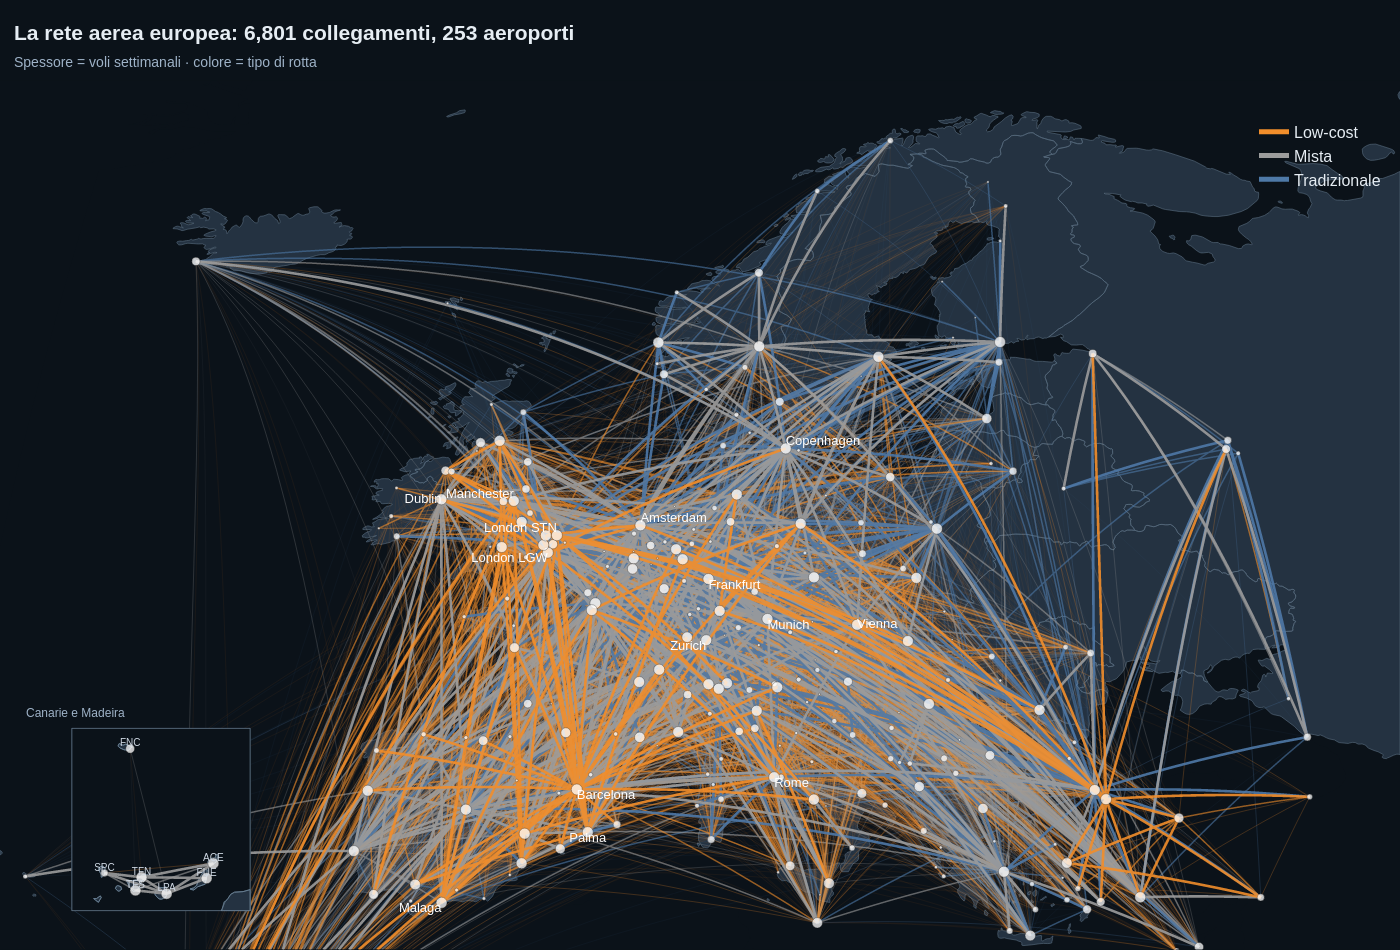

In [12]:
BINS = [(0, 6, 0.4, 0.16), (7, 20, 0.8, 0.30), (21, 50, 1.5, 0.60), (51, 10**6, 2.6, 0.90)]   # (min, max voli/sett, spessore, opacità)
BIN_LABEL = {0: "1–6", 1: "7–20", 2: "21–50", 3: "51+"}

DRAW_ORDER = ["Tradizionale", "Mista", "Low-cost"]   # ordine di disegno dei tipi dentro ogni fascia di frequenza

def add_edges(fig, E, tipi=DRAW_ORDER, row=None, col=None, opacity=0.5, show_legend=False, geo=None):
    for i, (lo, hi, w, op) in enumerate(BINS):      # prima le rotte poco frequenti, poi quelle più frequenti in primo piano
        for tipo in tipi:
            sub = E[(E.tipo == tipo) & E.voli_sett.between(lo, hi)]
            if sub.empty: continue
            lat, lon = [], []
            for r in sub.itertuples():
                lat += [r.lat_a, r.lat_b, None]; lon += [r.lon_a, r.lon_b, None]
            tr = go.Scattergeo(lat=lat, lon=lon, mode="lines", line=dict(width=w, color=COL[tipo]), opacity=op,
                               name=tipo, legendgroup=tipo, showlegend=(show_legend and i == 0), hoverinfo="skip")
            if geo: tr.update(geo=geo)
            fig.add_trace(tr, row=row, col=col) if row else fig.add_trace(tr)

def add_airports(fig, S, row=None, col=None, scale=0.3, geo=None):
    tr = go.Scattergeo(lat=S.lat, lon=S.lon, mode="markers", showlegend=False,
                       marker=dict(size=np.clip(np.sqrt(S.voli_sett) * scale, 2, 11), color="white",
                                   line=dict(width=0.4, color="#111"), opacity=0.75),
                       text=S.citta + " (" + S.index + ")<br>" + S.destinazioni.astype(str) + " destinazioni<br>" +
                            S.voli_sett.astype(int).astype(str) + " voli/sett.<br>quota con low-cost: " + (S.quota_lcc * 100).round().astype(int).astype(str) + "%",
                       hoverinfo="text")
    if geo: tr.update(geo=geo)
    fig.add_trace(tr, row=row, col=col) if row else fig.add_trace(tr)

# Cartina: coste a risoluzione 1:50 milioni,
# terra più chiara e confini più visibili del fondo scuro, così le linee risaltano ma si riconoscono i paesi.
GEO = dict(scope="europe", projection_type="natural earth", lonaxis_range=[-27, 43], lataxis_range=[34, 71.5],
           resolution=50, showland=True, landcolor="#243241", showocean=True, oceancolor="#0b1219", showcountries=True,
           countrycolor="#5b7082", countrywidth=0.6, coastlinecolor="#6b8195", coastlinewidth=0.7, showlakes=False,
           bgcolor="#0b1219", framewidth=0)

def add_hub_labels(fig, S, n=14):
    """Etichette con il nome dei principali aeroporti (per numero di destinazioni) per orientarsi sulla cartina."""
    top = S.nlargest(n, "destinazioni")
    POS = {"AMS": "top right", "FRA": "bottom right", "STN": "top left", "LGW": "bottom left", "MAN": "top left", "DUB": "middle left",
           "BCN": "bottom right", "PMI": "bottom center", "MUC": "bottom right", "FCO": "bottom right", "VIE": "middle right",
           "CPH": "top right", "AGP": "bottom left", "ZRH": "bottom left", "EDI": "top left"}
    fig.add_trace(go.Scattergeo(lat=top.lat, lon=top.lon, mode="text", text=labels(top), textposition=[POS.get(i, "top right") for i in top.index],
                                textfont=dict(size=13, color="#ffffff"), showlegend=False, hoverinfo="skip"))

def add_inset(fig, E, S):
    """Riquadro per Canarie e Madeira: sono molto più a sud-ovest del resto e sulla cartina principale restano tagliate."""
    in_box = lambda lat, lon: lat.between(27, 34) & lon.between(-19, -12)
    Ei = E[in_box(E.lat_a, E.lon_a) & in_box(E.lat_b, E.lon_b)]
    Si = S[in_box(S.lat, S.lon)]
    add_edges(fig, Ei, geo="geo2")
    add_airports(fig, Si, geo="geo2", scale=0.35)
    fig.add_trace(go.Scattergeo(lat=Si.lat, lon=Si.lon, mode="text", text=Si.index, textposition="top center",
                                textfont=dict(size=10, color="#cfd8e3"), showlegend=False, hoverinfo="skip", geo="geo2"))
    fig.update_layout(geo=dict(domain=dict(x=[0, 1], y=[0, 1])),   # senza questo Plotly rimpicciolisce la mappa principale quando c'è il riquadro
                      geo2=dict(domain=dict(x=[0.015, 0.215], y=[0.045, 0.255]), scope="world", projection_type="mercator",
                                lonaxis_range=[-19, -12.2], lataxis_range=[27.4, 33.4], resolution=50,
                                showland=True, landcolor="#243241", showocean=True, oceancolor="#0b1219",
                                showcountries=True, countrycolor="#5b7082", coastlinecolor="#6b8195", coastlinewidth=0.7,
                                bgcolor="#0b1219", showframe=True, framecolor="#6b8195", framewidth=1))
    fig.add_annotation(x=0.017, y=0.262, xref="paper", yref="paper", text="Canarie e Madeira", showarrow=False,
                       xanchor="left", yanchor="bottom", font=dict(size=12, color="#9fb3c8"))

fig = go.Figure()
add_edges(fig, edges)
add_airports(fig, stats)
for t in ORDER:   # voci di legenda a piena opacità
    fig.add_trace(go.Scattergeo(lat=[None], lon=[None], mode="lines", line=dict(width=4, color=COL[t]), name=t))
fig.update_geos(**GEO)
fig.update_layout(template="plotly_dark", paper_bgcolor="#0b1219", font=dict(family="Arial", color="#e6edf3", size=15),
                  title=dict(text=f"<b>La rete aerea europea: {len(edges):,} collegamenti, {len(stats):,} aeroporti</b><br><span style='font-size:14px;color:#9fb3c8'>Spessore = voli settimanali · colore = tipo di rotta</span>", x=0.01),
                  margin=dict(l=0, r=0, t=80, b=0), legend=dict(orientation="h", y=0.96, x=0.99, xanchor="right", yanchor="top", bgcolor="rgba(0,0,0,0)", font=dict(size=16), itemsizing="constant"))
add_hub_labels(fig, stats)
add_inset(fig, edges, stats)
show(fig, "01_mappa_rete", w=1400, h=950)

**Cosa si vede.** La rete è un enorme sistema *point-to-point*: **6.801 collegamenti** tra **253 aeroporti** di 42 paesi, per quasi **128.000 voli a settimana**. Qui le tratte più frequenti sono in primo piano, quelle rare restano sullo sfondo. Il fascio arancione (low-cost) è molto fitto tra Regno Unito/Irlanda/Europa centrale e il Mediterraneo (Spagna, Canarie, Italia, Grecia, Turchia); le dorsali nordiche e quelle al centro sono in prevalenza blu o grigie. L'immagine mostra soprattutto una cosa: la **densità** della rete, difficile da leggere nel dettaglio, per questo nella mappa successiva isoliamo i corridoi principali.

### 6.1b Le autostrade del cielo: i 300 collegamenti più frequenti
La mappa completa è molto densa. Teniamo solo i **300 collegamenti con più voli settimanali**: lo spessore è ora proporzionale ai voli e si leggono i nodi principali.

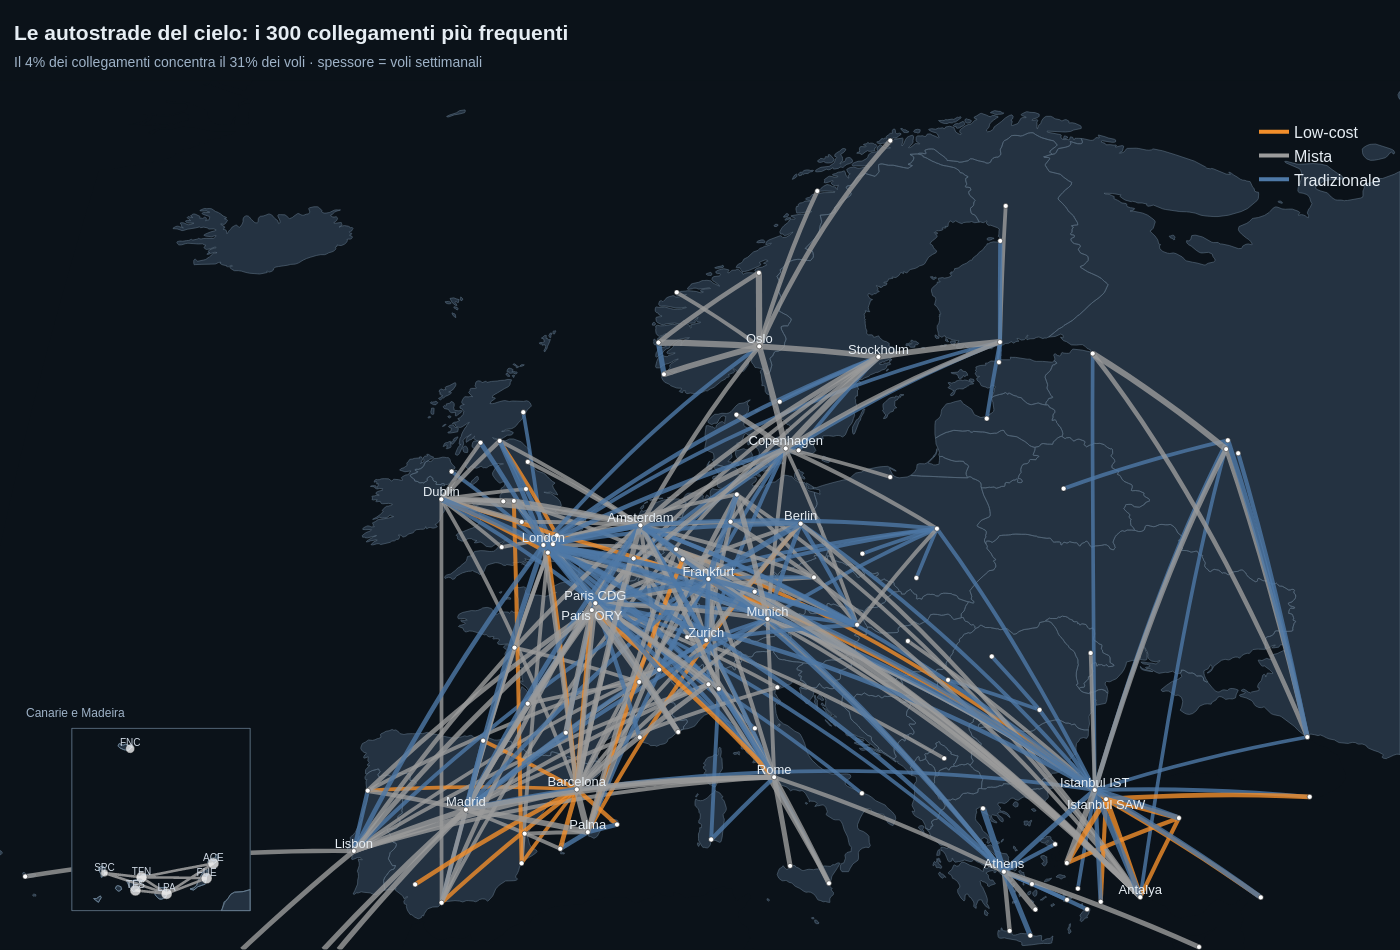

I 300 collegamenti più frequenti (4.4% del totale) concentrano il 30.9% dei voli settimanali.
tipo
Mista           145
Tradizionale    129
Low-cost         26


In [13]:
top_e = edges.nlargest(300, "voli_sett")
vmax = top_e.voli_sett.max()
fig = go.Figure()
for r in top_e.sort_values("voli_sett").itertuples():
    fig.add_trace(go.Scattergeo(lat=[r.lat_a, r.lat_b], lon=[r.lon_a, r.lon_b], mode="lines", showlegend=False, hoverinfo="text",
                                text=f"{r.a} – {r.b}: {r.voli_sett} voli/sett. ({r.tipo})",
                                line=dict(width=0.8 + 6 * np.sqrt(r.voli_sett / vmax), color=COL[r.tipo]), opacity=0.8))
nodes = stats.loc[sorted(set(top_e.a) | set(top_e.b))].copy()
nodes["w"] = pd.concat([top_e.groupby("a").voli_sett.sum(), top_e.groupby("b").voli_sett.sum()]).groupby(level=0).sum()
lab = nodes.nlargest(22, "w")
fig.add_trace(go.Scattergeo(lat=nodes.lat, lon=nodes.lon, mode="markers", showlegend=False, hoverinfo="skip",
                            marker=dict(size=5, color="white", line=dict(width=0.5, color="#111"))))
fig.add_trace(go.Scattergeo(lat=lab.lat, lon=lab.lon, mode="text", text=labels(lab), textposition=label_pos(lab),
                            textfont=dict(size=13, color="#e6edf3"), showlegend=False, hoverinfo="skip"))
for t in ORDER:
    fig.add_trace(go.Scattergeo(lat=[None], lon=[None], mode="lines", line=dict(width=4, color=COL[t]), name=t))
fig.update_geos(**GEO)
share300 = top_e.voli_sett.sum() / edges.voli_sett.sum()
fig.update_layout(template="plotly_dark", paper_bgcolor="#0b1219", font=dict(family="Arial", color="#e6edf3", size=15),
                  title=dict(text=f"<b>Le autostrade del cielo: i 300 collegamenti più frequenti</b><br><span style='font-size:14px;color:#9fb3c8'>Il {len(top_e)/len(edges):.0%} dei collegamenti concentra il {share300:.0%} dei voli · spessore = voli settimanali</span>", x=0.01),
                  margin=dict(l=0, r=0, t=80, b=0), legend=dict(orientation="h", y=0.96, x=0.99, xanchor="right", yanchor="top", bgcolor="rgba(0,0,0,0)", font=dict(size=16)))
add_inset(fig, top_e, stats)
show(fig, "01b_corridoi_principali", w=1400, h=950)
print(f"I 300 collegamenti più frequenti ({len(top_e)/len(edges):.1%} del totale) concentrano il {share300:.1%} dei voli settimanali.")
print(top_e.tipo.value_counts().to_string())

**Cosa si vede.** Il **4% dei collegamenti (300 su 6.801) concentra il 31% dei voli settimanali**. Sono le dorsali: un terzo sono tratte domestiche (Las Palmas–Tenerife, Barcellona–Palma, Oslo–Bergen, Oslo–Trondheim, Atene–Salonicco) e le altre collegano capitali e grandi scali (Stoccolma–Copenaghen, Stoccolma–Helsinki, Istanbul–Antalya). Un risultato controintuitivo: **solo 26 dei 300 corridoi sono puramente low-cost** (8% dei loro voli), contro 145 misti (51%) e 129 tradizionali (40%). Le low-cost dominano per *numero* di rotte e capillarità, mentre le tratte ad altissima frequenza sono quelle in cui operano anche compagnie tradizionali.

### 6.2 Due cieli a confronto: low-cost vs tradizionale

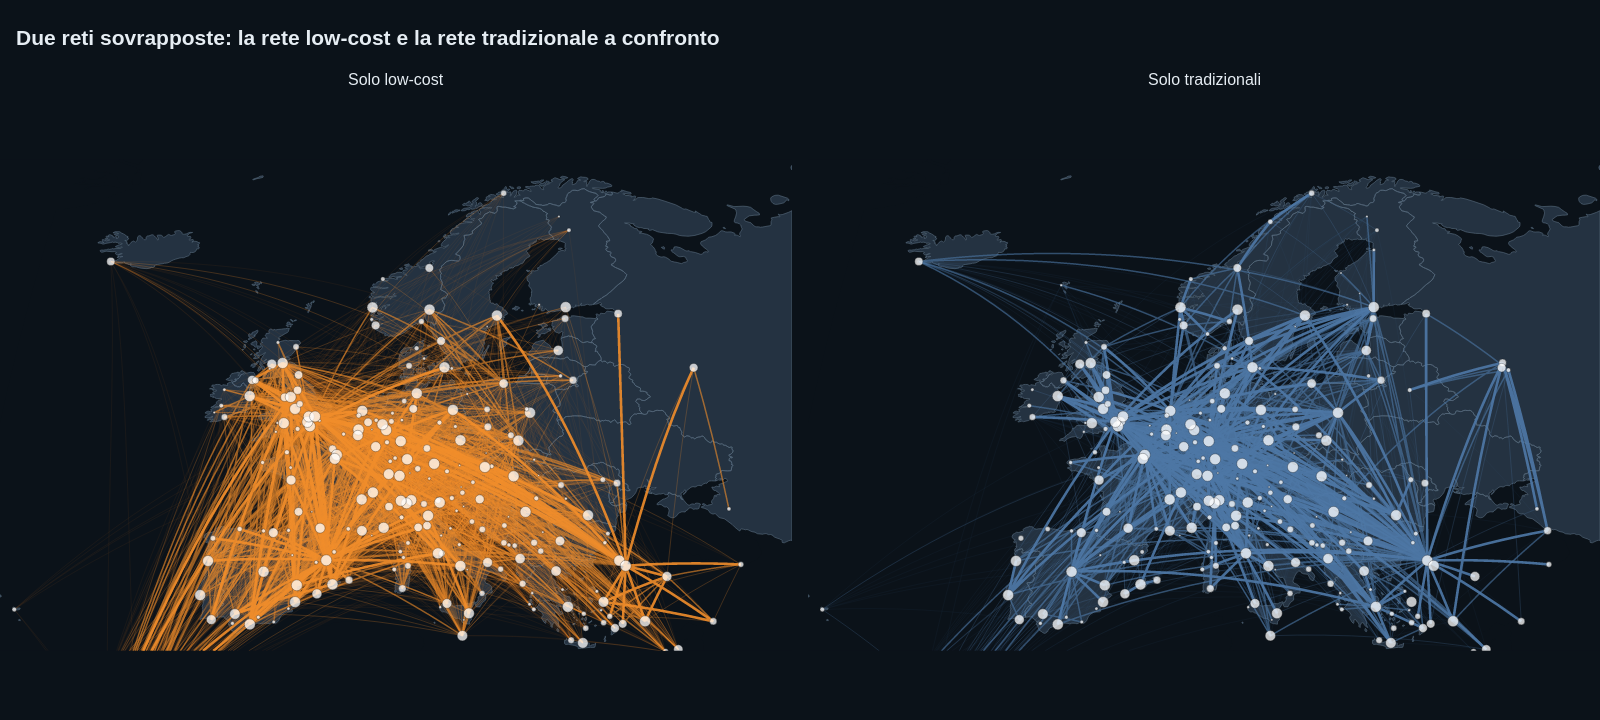

In [14]:
fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scattergeo"}] * 2],
                    subplot_titles=("Solo low-cost", "Solo tradizionali"), horizontal_spacing=0.01)
add_edges(fig, edges, tipi=["Low-cost"], row=1, col=1, opacity=0.55)
add_edges(fig, edges, tipi=["Tradizionale"], row=1, col=2, opacity=0.55)
S_l = stats[stats.index.isin(set(edges.loc[edges.tipo == "Low-cost", "a"]) | set(edges.loc[edges.tipo == "Low-cost", "b"]))]
add_airports(fig, S_l, row=1, col=1, scale=0.3)
S_t = stats[stats.index.isin(set(edges.loc[edges.tipo == "Tradizionale", "a"]) | set(edges.loc[edges.tipo == "Tradizionale", "b"]))]
add_airports(fig, S_t, row=1, col=2, scale=0.3)
fig.update_geos(**GEO)
fig.update_layout(template="plotly_dark", paper_bgcolor="#0b1219", font=dict(family="Arial", color="#e6edf3", size=15),
                  title=dict(text="<b>Due reti sovrapposte: la rete low-cost e la rete tradizionale a confronto</b>", x=0.01),
                  margin=dict(l=0, r=0, t=90, b=0), showlegend=False)
show(fig, "02_low_cost_vs_tradizionale", w=1600, h=720)

**Lettura.** Separando i due mondi si vede bene la differenza di geografia: la rete **low-cost** (a sinistra) collega soprattutto le aree di partenza del Nord (Regno Unito, Irlanda, Germania) alle destinazioni turistiche del Sud, con fasci molto fitti verso Spagna e Canarie; la rete **tradizionale** (a destra) è più centrata sull'Europa continentale e sui paesi nordici, con collegamenti verso i grandi scali.

### 6.3 Gli hub più connessi

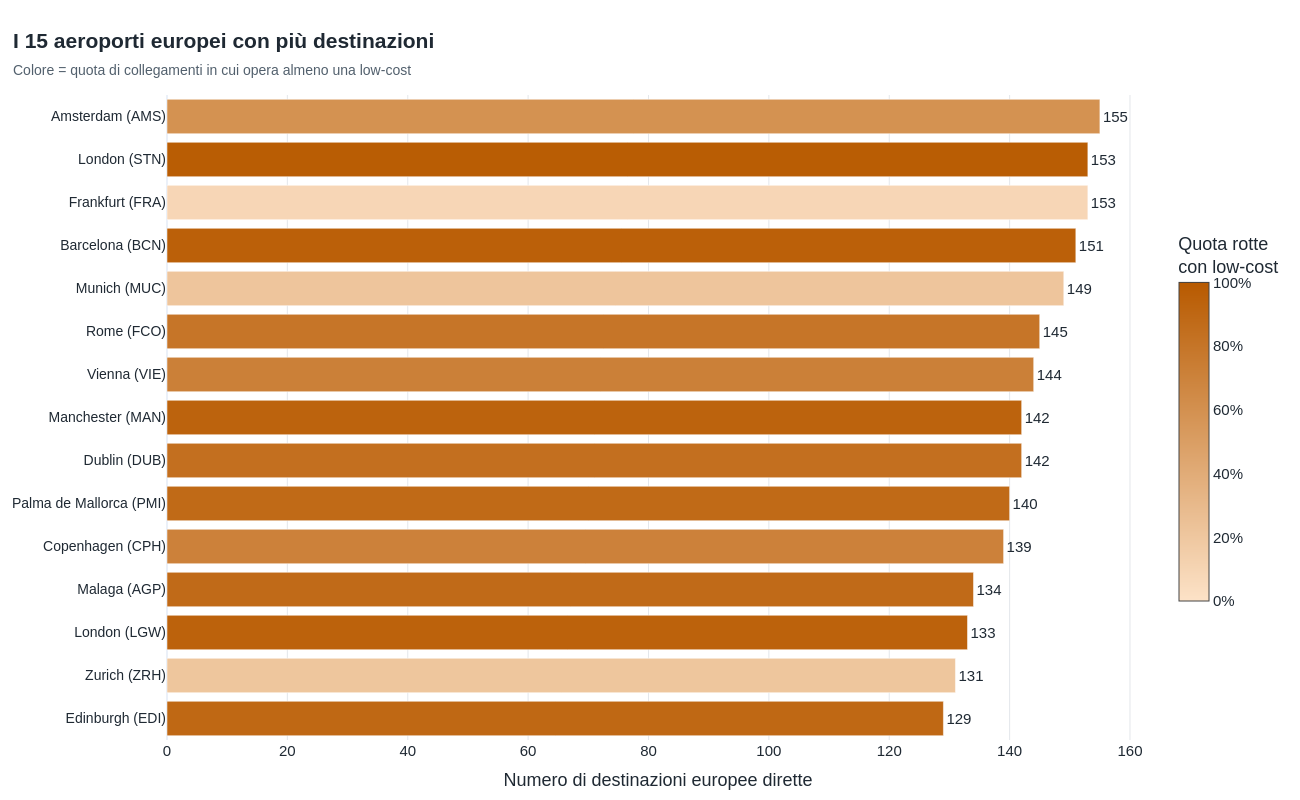

In [15]:
top = stats.nlargest(15, "destinazioni").sort_values("destinazioni")
fig = go.Figure(go.Bar(
    y=top.citta + " (" + top.index + ")", x=top.destinazioni, orientation="h",
    marker=dict(color=top.quota_lcc, colorscale=[[0, "#FDE3C8"], [1, "#B85A00"]], cmin=0, cmax=1,
                colorbar=dict(title="Quota rotte<br>con low-cost", tickformat=".0%", len=0.6)),
    text=top.destinazioni, textposition="outside",
    hovertemplate="%{y}<br>%{x} destinazioni<br>%{customdata[0]:,.0f} voli/sett.<br>%{customdata[1]:.0%} rotte con low-cost<extra></extra>",
    customdata=np.c_[top.voli_sett, top.quota_lcc]))
base_layout(fig, "I 15 aeroporti europei con più destinazioni", "Colore = quota di collegamenti in cui opera almeno una low-cost")
fig.update_xaxes(title="Numero di destinazioni europee dirette", gridcolor="#e4e7eb"); fig.update_yaxes(tickfont=dict(size=14))
show(fig, "03_top_hub", w=1300, h=800)

**Cosa ci dice.** Amsterdam è l'aeroporto con più destinazioni europee dirette (155), seguita da Londra Stansted e Francoforte (153) e Barcellona (151). Ma i colori mostrano che "hub" significa due cose diverse. **Francoforte, Londra Heathrow, Istanbul, Monaco e Zurigo** sono scali storici di compagnie tradizionali (solo il 9–22% dei collegamenti ha una low-cost), mentre **Stansted (98%), Barcellona (95%), Manchester e Gatwick (94%)** sono grandi basi low-cost. Amsterdam, Vienna e Copenaghen stanno nel mezzo (59–72%). Il ranking misura le destinazioni, non i passeggeri.

**Due modelli di hub a confronto.** Ogni punto è un aeroporto: asse x = destinazioni, asse y = quota di collegamenti con almeno una low-cost, dimensione = voli settimanali.

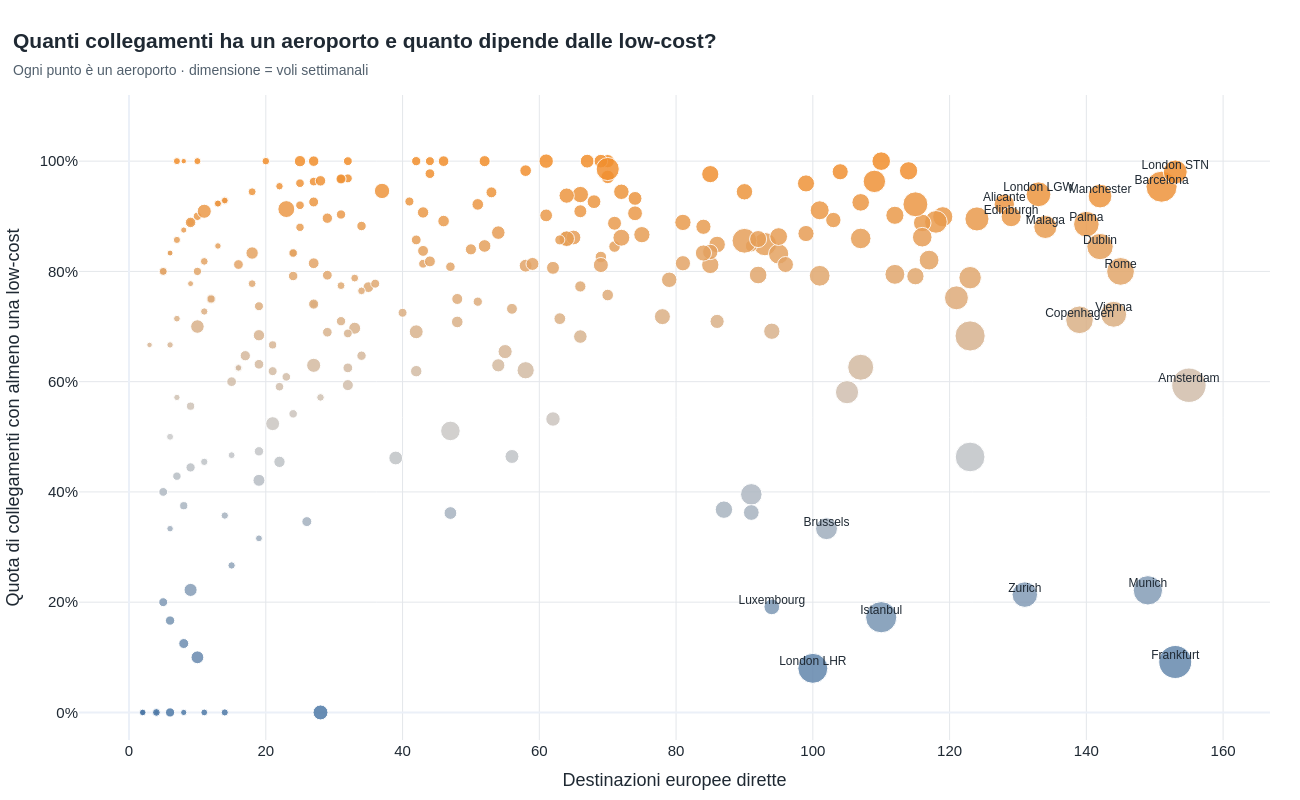

In [16]:
lab = stats[(stats.destinazioni >= 125) | ((stats.destinazioni >= 90) & (stats.quota_lcc < 0.35))]
fig = go.Figure(go.Scatter(
    x=stats.destinazioni, y=stats.quota_lcc, mode="markers",
    marker=dict(size=np.sqrt(stats.voli_sett) * 0.35 + 4, color=stats.quota_lcc, colorscale=[[0, "#4E79A7"], [0.5, "#C9C9C9"], [1, "#F28E2B"]], cmin=0, cmax=1,
                line=dict(width=1, color="white"), opacity=0.85),
    text=stats.citta + " (" + stats.index + ")", hovertemplate="%{text}<br>%{x} destinazioni<br>%{y:.0%} rotte con low-cost<extra></extra>"))
fig.add_trace(go.Scatter(x=lab.destinazioni, y=lab.quota_lcc, mode="text", text=labels(lab), textposition="top center", textfont=dict(size=12), showlegend=False, hoverinfo="skip"))
base_layout(fig, "Quanti collegamenti ha un aeroporto e quanto dipende dalle low-cost?", "Ogni punto è un aeroporto · dimensione = voli settimanali")
fig.update_layout(showlegend=False)
fig.update_xaxes(title="Destinazioni europee dirette", gridcolor="#e4e7eb"); fig.update_yaxes(title="Quota di collegamenti con almeno una low-cost", tickformat=".0%", range=[-0.05, 1.12], gridcolor="#e4e7eb")
show(fig, "03b_modelli_di_hub", w=1300, h=800)

### 6.4 Le compagnie

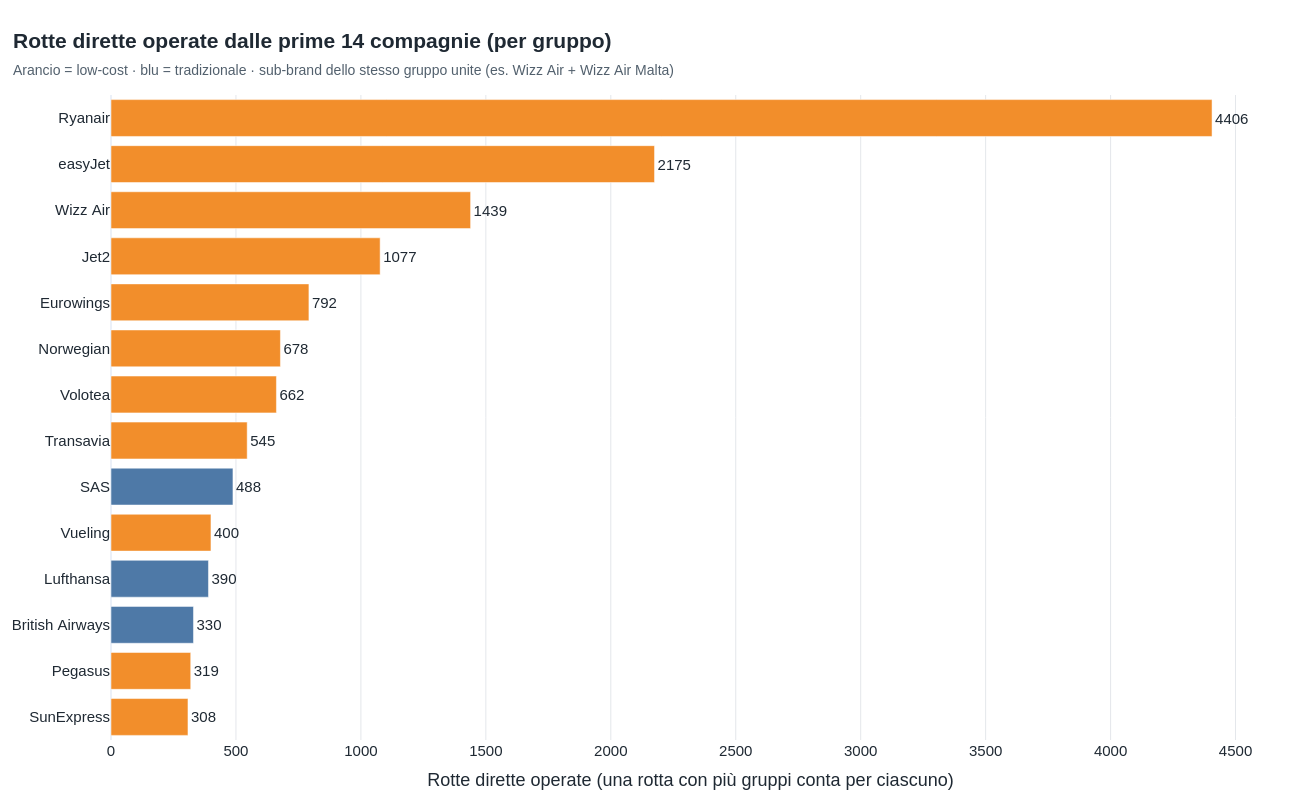

Le prime 5 compagnie coprono il 50% delle coppie rotta-compagnia; le rotte con almeno una low-cost sono il 77% del totale.


In [17]:
tc = top_carriers.head(14).sort_values("rotte")
fig = go.Figure(go.Bar(y=tc.index, x=tc.rotte, orientation="h",
                       marker_color=[COL["Low-cost"] if l else COL["Tradizionale"] for l in tc.low_cost],
                       text=tc.rotte, textposition="outside"))
base_layout(fig, "Rotte dirette operate dalle prime 14 compagnie (per gruppo)", "Arancio = low-cost · blu = tradizionale · sub-brand dello stesso gruppo unite (es. Wizz Air + Wizz Air Malta)")
fig.update_xaxes(title="Rotte dirette operate (una rotta con più gruppi conta per ciascuno)", gridcolor="#e4e7eb")
show(fig, "04_compagnie", w=1300, h=800)
share_top5 = top_carriers.head(5).rotte.sum() / top_carriers.rotte.sum()
lcc_share_routes = (df.has_lcc).mean()
print(f"Le prime 5 compagnie coprono il {share_top5:.0%} delle coppie rotta-compagnia; le rotte con almeno una low-cost sono il {lcc_share_routes:.0%} del totale.")

**Cosa ci dice.** Il mercato è fortemente guidato dalle low-cost: **Ryanair (con le sue sub-brand) opera oltre 4.400 rotte**, circa il doppio di easyJet, e le prime 5 compagnie coprono circa il 50% di tutte le coppie rotta-compagnia. Delle prime 14, 11 sono low-cost; la prima tradizionale è SAS, seguita da Lufthansa e British Airways. Complessivamente il **77% delle rotte** ha almeno una low-cost e il **67% dei voli settimanali** viaggia su collegamenti con presenza low-cost.

### 6.5 L'evoluzione della rete: quando sono nate le rotte
Il dataset è un'**istantanea della programmazione di agosto 2025**, non una serie storica. Possiamo però ricostruire l'evoluzione dalla data del **primo volo**: ogni rotta già operativa all'estrazione viene assegnata all'anno in cui è nata.

Tre cautele metodologiche:
- il campo `first_flight` ha un enorme picco nel **2018** (6.000 righe su 18.111): è l'avvio della raccolta dati del sito, non un boom reale. Accorpiamo tutto ciò che è ≤2018 in un'unica barra "≤2018 (rotte storiche)".
- vediamo solo le rotte **sopravvissute**: le rotte nate e poi chiuse non ci sono, quindi gli anni più vecchi sono sottostimati.
- le rotte con primo volo **dopo l'11/8/2025** sono solo annunciate (261 collegamenti): le escludiamo, e il **2025 è parziale** (fino all'estrazione, segnato 2025*). Per circa il 15% dei collegamenti la data è sconosciuta ed è esclusa da questa sezione.

Collegamenti con data nota: 5,812 su 6,801  |  già operativi all'estrazione: 5,551  |  solo annunciati: 261


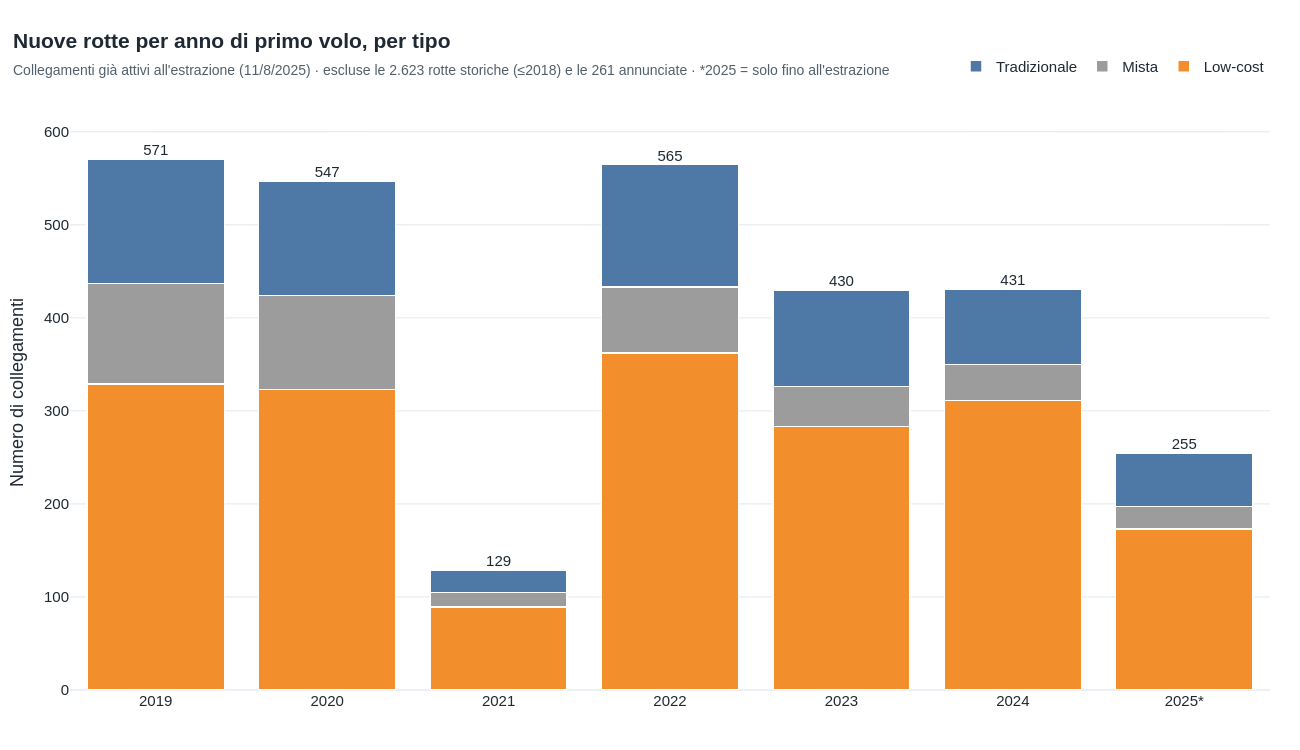

tipo,Low-cost,Mista,Tradizionale
anno_lbl,,,
≤2018,1480,632,511
2019,329,108,134
2020,323,101,123
2021,89,16,24
2022,362,71,132
2023,283,43,104
2024,311,39,81
2025*,173,24,58


In [18]:
# Le rotte con primo volo DOPO la data di estrazione dei dati sono solo annunciate: non le contiamo come "nate" in un anno
ed_all = edges.dropna(subset=["primo_volo"]).copy()
ann = ed_all[ed_all.primo_volo > EXTRACTION_DATE]            # annunciate (primo volo futuro rispetto all'estrazione)
ed = ed_all[ed_all.primo_volo <= EXTRACTION_DATE].copy()     # già operative all'estrazione
ed["anno"] = ed.primo_volo.dt.year.clip(lower=2018)
ed["anno_lbl"] = ed.anno.astype(str).replace({"2018": "≤2018", "2025": "2025*"})
print(f"Collegamenti con data nota: {len(ed_all):,} su {len(edges):,}  |  già operativi all'estrazione: {len(ed):,}  |  solo annunciati: {len(ann):,}")

LBL = ["≤2018"] + [str(y) for y in range(2019, 2025)] + ["2025*"]
coh = ed.groupby(["anno_lbl", "tipo"]).size().unstack(fill_value=0).reindex(columns=ORDER).reindex(LBL)

c5 = coh.drop(index="≤2018")        # le rotte storiche (≤2018) sono troppe e schiacciano il resto: le riportiamo nel sottotitolo
fig = go.Figure()
for t in ORDER:
    fig.add_bar(x=c5.index, y=c5[t], name=t, marker_color=COL[t], marker_line=dict(width=1.5, color="white"))
fig.add_trace(go.Scatter(x=c5.index, y=c5.sum(axis=1), mode="text", text=c5.sum(axis=1).astype(str), textposition="top center", showlegend=False, textfont=dict(size=15)))
n_hist = f"{int(coh.loc['≤2018'].sum()):,}".replace(",", ".")
base_layout(fig, "Nuove rotte per anno di primo volo, per tipo", f"Collegamenti già attivi all'estrazione (11/8/2025) · escluse le {n_hist} rotte storiche (≤2018) e le {len(ann)} annunciate · *2025 = solo fino all'estrazione")
fig.update_layout(barmode="stack"); fig.update_yaxes(title="Numero di collegamenti", gridcolor="#e4e7eb", range=[0, c5.sum(axis=1).max() * 1.12])
show(fig, "05_nuove_rotte_per_anno", w=1300, h=750)
coh

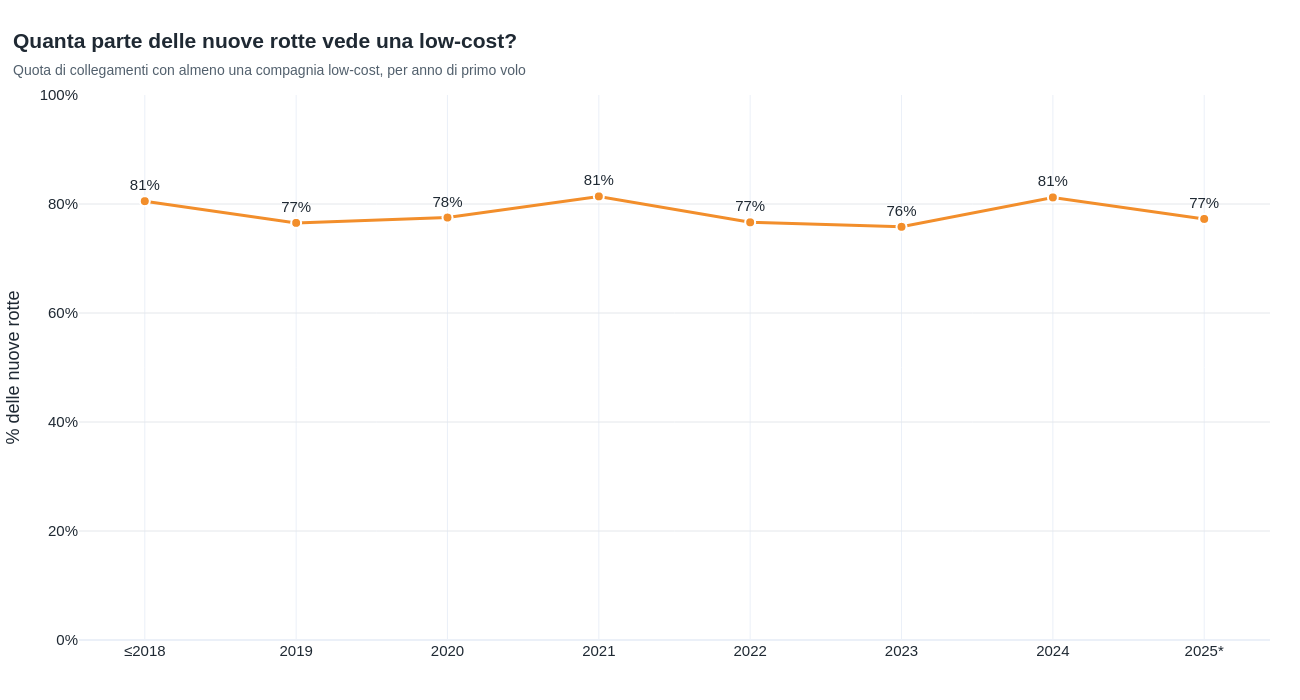

anno_lbl,≤2018,2019,2020,2021,2022,2023,2024,2025*
quota_lcc,0.805,0.765,0.775,0.814,0.766,0.758,0.812,0.773


In [19]:
# Quota di rotte con presenza low-cost tra le NUOVE rotte di ogni anno
quota = ed.groupby("anno_lbl").has_lcc.mean().reindex(coh.index)
fig = go.Figure(go.Scatter(x=quota.index, y=quota, mode="lines+markers+text", line=dict(color=COL["Low-cost"], width=3),
                           marker=dict(size=10, line=dict(width=2, color="white")), text=(quota * 100).round().astype(int).astype(str) + "%",
                           textposition="top center", textfont=dict(color=INK)))
base_layout(fig, "Quanta parte delle nuove rotte vede una low-cost?", "Quota di collegamenti con almeno una compagnia low-cost, per anno di primo volo")
fig.update_yaxes(title="% delle nuove rotte", tickformat=".0%", range=[0, 1], gridcolor="#e4e7eb")
show(fig, "06_quota_lcc_per_anno", w=1300, h=700)
quota.round(3).to_frame("quota_lcc").T

**Cosa ci dice (con cautela).** Dopo la barra delle rotte storiche (≤2018, circa 2.600 collegamenti), si nota il crollo delle nuove rotte nel **2021** (129, effetto pandemia) e la ripartenza dal 2022 (circa 430–565 nuovi collegamenti l'anno nel 2022–2024; il 2025 è parziale). La quota di nuove rotte con una low-cost resta **stabile intorno al 76–81%** in tutti gli anni: non c'è un'ulteriore crescita del peso low-cost nelle nuove aperture, perché il modello low-cost è già dominante nella rete. Attenzione: vediamo solo le rotte sopravvissute, quindi il passato è sottostimato.

### 6.6 Hub storici vs aeroporti regionali
Chiamiamo **grandi hub** i 25 aeroporti con più destinazioni. Per ogni anno guardiamo che tipo di collegamenti nascono: tra due hub, tra un hub e uno scalo regionale, oppure tra due scali regionali (i collegamenti "point-to-point" che aggirano gli hub).

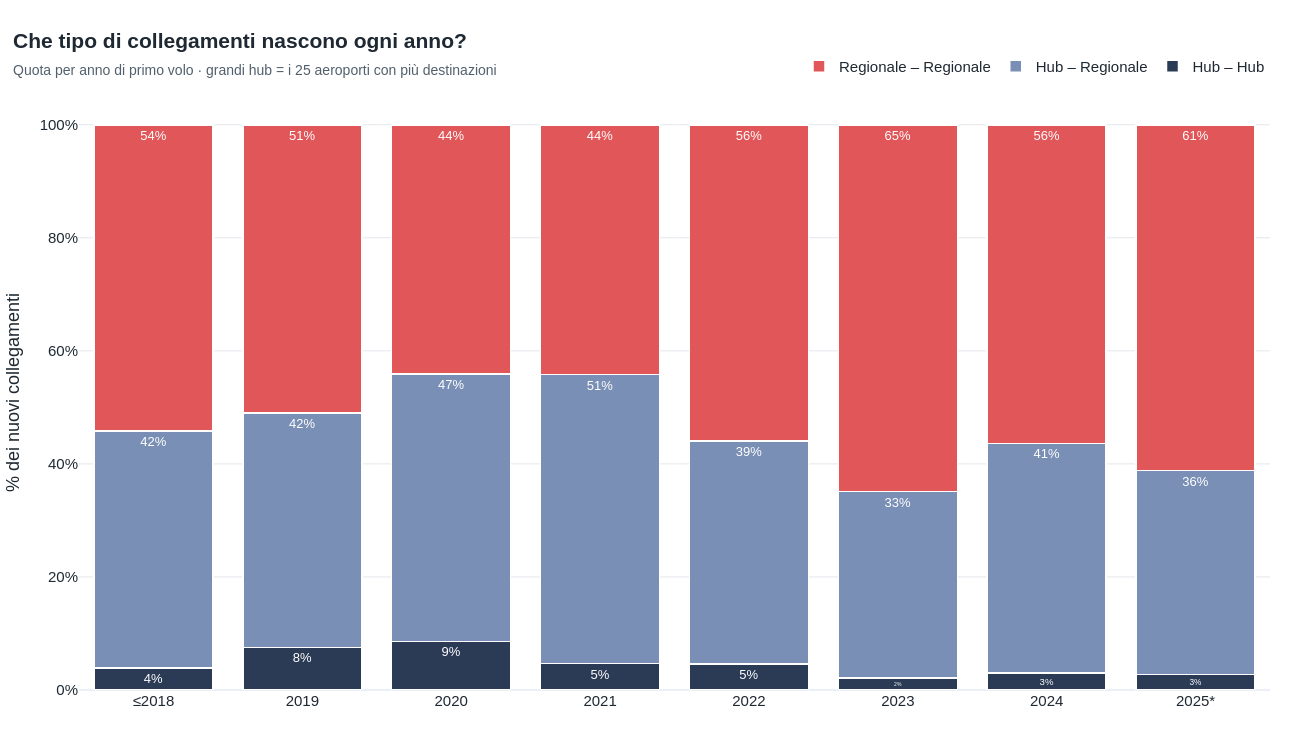

Composizione dell'intera rete:
categoria
Regionale – Regionale    0.550
Hub – Regionale          0.407
Hub – Hub                0.043


In [20]:
cat = ed.groupby(["anno_lbl", "categoria"]).size().unstack(fill_value=0).reindex(coh.index)
cat_pct = cat.div(cat.sum(axis=1), axis=0)[["Hub – Hub", "Hub – Regionale", "Regionale – Regionale"]]
cat_col = {"Hub – Hub": "#2B3A55", "Hub – Regionale": "#7A8FB5", "Regionale – Regionale": "#E15759"}
fig = go.Figure()
for k in cat_pct.columns:
    fig.add_bar(x=cat_pct.index, y=cat_pct[k], name=k, marker_color=cat_col[k], marker_line=dict(width=1.5, color="white"),
                text=(cat_pct[k] * 100).round().astype(int).astype(str) + "%", textposition="inside", textfont=dict(color="white", size=13))
base_layout(fig, "Che tipo di collegamenti nascono ogni anno?", f"Quota per anno di primo volo · grandi hub = i {N_HUB} aeroporti con più destinazioni")
fig.update_layout(barmode="stack"); fig.update_yaxes(title="% dei nuovi collegamenti", tickformat=".0%", gridcolor="#e4e7eb")
show(fig, "07_hub_vs_regionali", w=1300, h=750)
print("Composizione dell'intera rete:"); print(edges.categoria.value_counts(normalize=True).round(3).to_string())

**Cosa ci dice.** La rete oggi è fatta per il **55% di collegamenti regionale–regionale**, il 41% hub–regionale e solo il **4% hub–hub**. Tra le nuove rotte, la quota regionale–regionale passa dal 54% (≤2018) a **56–65% dal 2022 in poi** (era il 44–51% nel 2019–2021, gli anni della pandemia), mentre i collegamenti tra due grandi hub restano marginali (2–5% dal 2022). I dati sono compatibili con una crescita dei collegamenti diretti tra scali secondari che aggirano gli hub, in coerenza con il modello low-cost. (Definizione: hub = i 25 aeroporti con più destinazioni.)

### 6.7 Matrice origine-destinazione tra paesi
Aggreghiamo i voli settimanali per coppia di paesi (matrice O-D, entrambi i versi). La diagonale rappresenta i voli interni a un paese.

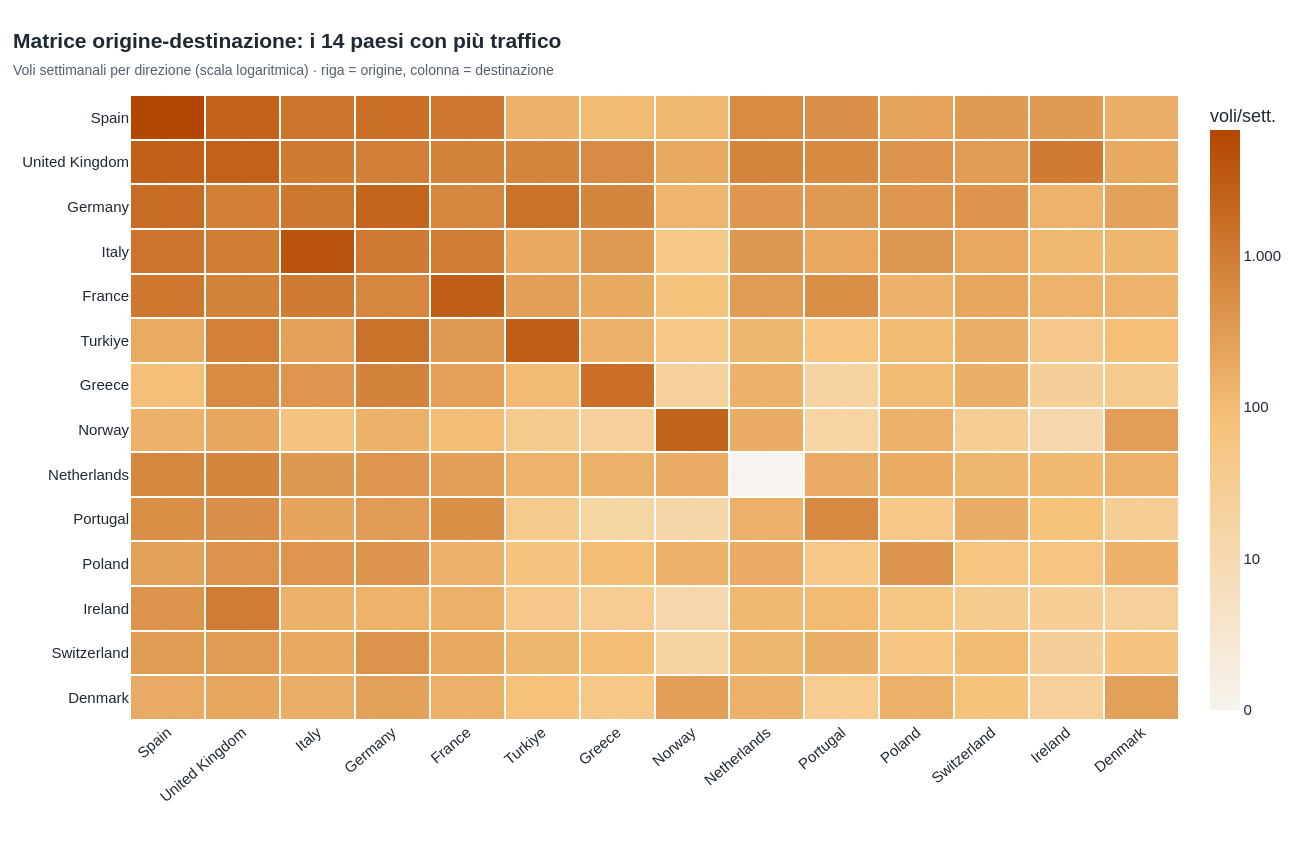

Quota di voli interni (domestici) sul totale in uscita:
Norway            56%
Spain             38%
Turkiye           34%
Italy             34%
Greece            31%
France            30%
Portugal          18%
United Kingdom    18%
Germany           17%
Poland            11%
Denmark           10%
Switzerland        4%
Ireland            1%
Netherlands        0%


In [21]:
od = pd.concat([df.assign(o=df.departure_country, d=df.arrival_airport_country)])
# i nomi dei paesi lato arrivo differiscono per alcuni paesi: usiamo l'anagrafica degli aeroporti per coerenza
od["d"] = od.iata_to.map(airports.paese)
od_m = od.pivot_table(index="o", columns="d", values="flights_per_week", aggfunc="sum", fill_value=0)
top_c = od_m.sum(axis=1).add(od_m.sum(axis=0), fill_value=0).nlargest(14).index
M = od_m.loc[top_c, top_c]
M = M.loc[M.sum(axis=1).sort_values(ascending=False).index, M.sum(axis=0).sort_values(ascending=False).index]
fig = go.Figure(go.Heatmap(z=np.log10(M.values + 1), x=M.columns, y=M.index, customdata=M.values,
                           colorscale=[[0, "#f7f4ef"], [0.5, "#f6c27a"], [1, "#b34700"]], xgap=2, ygap=2,
                           colorbar=dict(title="voli/sett.", tickvals=[0, 1, 2, 3, 4], ticktext=["0", "10", "100", "1.000", "10.000"]),
                           hovertemplate="%{y} → %{x}<br>%{customdata:,.0f} voli/sett.<extra></extra>"))
base_layout(fig, "Matrice origine-destinazione: i 14 paesi con più traffico", "Voli settimanali per direzione (scala logaritmica) · riga = origine, colonna = destinazione")
fig.update_xaxes(tickangle=-40, side="bottom"); fig.update_yaxes(autorange="reversed"); fig.update_layout(margin=dict(l=130, r=30, t=95, b=130))
show(fig, "08_matrice_od", w=1300, h=850)
dom = pd.Series({p: od_m.loc[p, p] / od_m.loc[p].sum() for p in top_c}).sort_values(ascending=False)
print("Quota di voli interni (domestici) sul totale in uscita:"); print((dom * 100).round(0).astype(int).astype(str).add("%").to_string())

**Cosa ci dice.** Spagna, Regno Unito, Italia, Germania e Francia formano il nucleo più scuro della matrice. Gran parte del traffico è **interno ai paesi** (diagonale): Norvegia 56% dei voli in uscita, Spagna 38%, Turchia e Italia 34%, Grecia 31%, mentre i Paesi Bassi non hanno voli interni. I corridoi internazionali più intensi sono Spagna–Regno Unito (circa 5.300 voli a settimana) e Germania–Spagna (circa 3.400), seguiti da Germania–Turchia e Italia–Spagna: flussi coerenti con il turismo verso il Mediterraneo.

### 6.8 Prezzo: low-cost vs tradizionale
> Il campo `price` è descritto su Kaggle solo come *estimated price* (stima in €, non documentata), quindi lo usiamo solo come **indicazione**, escludendo valori nulli e outlier oltre 1.000 €.

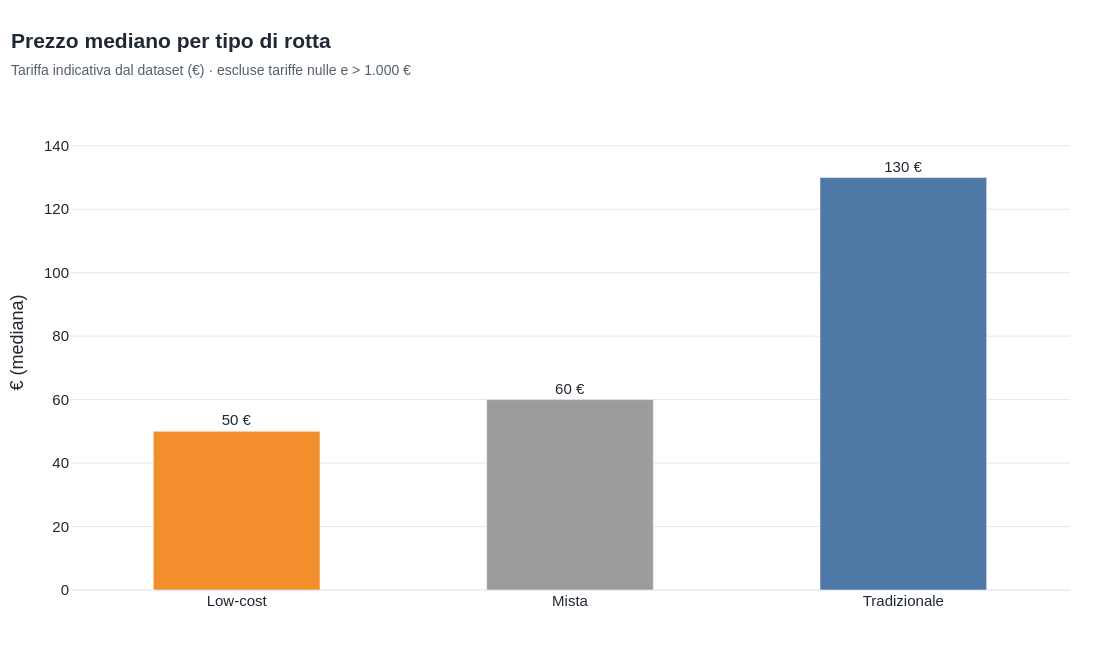

In [22]:
pz = df[df.price.between(1, 1000)]
med = pz.groupby("tipo").price.median().reindex(ORDER)
fig = go.Figure(go.Bar(x=med.index, y=med, marker_color=[COL[t] for t in med.index], text=med.round().astype(int).astype(str) + " €", textposition="outside", width=0.5))
base_layout(fig, "Prezzo mediano per tipo di rotta", "Tariffa indicativa dal dataset (€) · escluse tariffe nulle e > 1.000 €")
fig.update_yaxes(title="€ (mediana)", gridcolor="#e4e7eb", range=[0, med.max() * 1.2]); fig.update_layout(showlegend=False)
show(fig, "09_prezzo", w=1100, h=650)

**Indicazione.** Il prezzo mediano delle rotte solo low-cost è circa **50 €**, quello delle rotte miste 60 € e quello delle rotte solo tradizionali **130 €**: le tariffe low-cost sono meno della metà di quelle tradizionali. Da prendere come ordine di grandezza, dato che il campo non è documentato.

## 7. Clustering degli aeroporti (K-means e mean-shift)

Finora la distinzione tra "scali storici delle compagnie tradizionali" e "basi low-cost" è stata fatta **a occhio** sullo scatter. Con il clustering proviamo a farla emergere dai dati: raggruppiamo gli aeroporti in base a tre caratteristiche e vediamo se i gruppi coincidono con quelli ipotizzati.

- **Variabili:** numero di destinazioni, voli settimanali (in scala logaritmica, perché molto asimmetrici) e quota di collegamenti con almeno una low-cost.
- **Standardizzazione:** le variabili hanno scale molto diverse (la quota low-cost va da 0 a 1, i voli settimanali da pochi a migliaia), quindi le standardizziamo (media 0, deviazione 1) prima di calcolare le distanze.
- **K-means** è l'algoritmo principale (richiede k); **mean-shift** trova da solo il numero di gruppi e lo usiamo come confronto di robustezza.

In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn.metrics import silhouette_score, adjusted_rand_score

feat = pd.DataFrame({"destinazioni": stats.destinazioni,
                     "voli_sett (log)": np.log1p(stats.voli_sett),
                     "quota_lcc": stats.quota_lcc})
Z = StandardScaler().fit_transform(feat)          # media 0, deviazione standard 1 per ogni variabile
feat.describe().round(2)

,destinazioni,voli_sett (log),quota_lcc
count,253.00,253.00,253.00
mean,53.76,6.13,0.73
std,41.16,1.35,0.26
min,2.00,1.95,0.00
25%,19.00,5.20,0.63
50%,43.00,6.14,0.81
75%,85.00,7.11,0.90
max,155.00,8.93,1.00


**Distribuzioni delle variabili usate nel clustering.** Prima di standardizzare guardiamo come sono fatte: destinazioni e voli settimanali sono molto asimmetrici (pochi grandi scali, tanti piccoli): per questo i voli entrano in scala logaritmica.

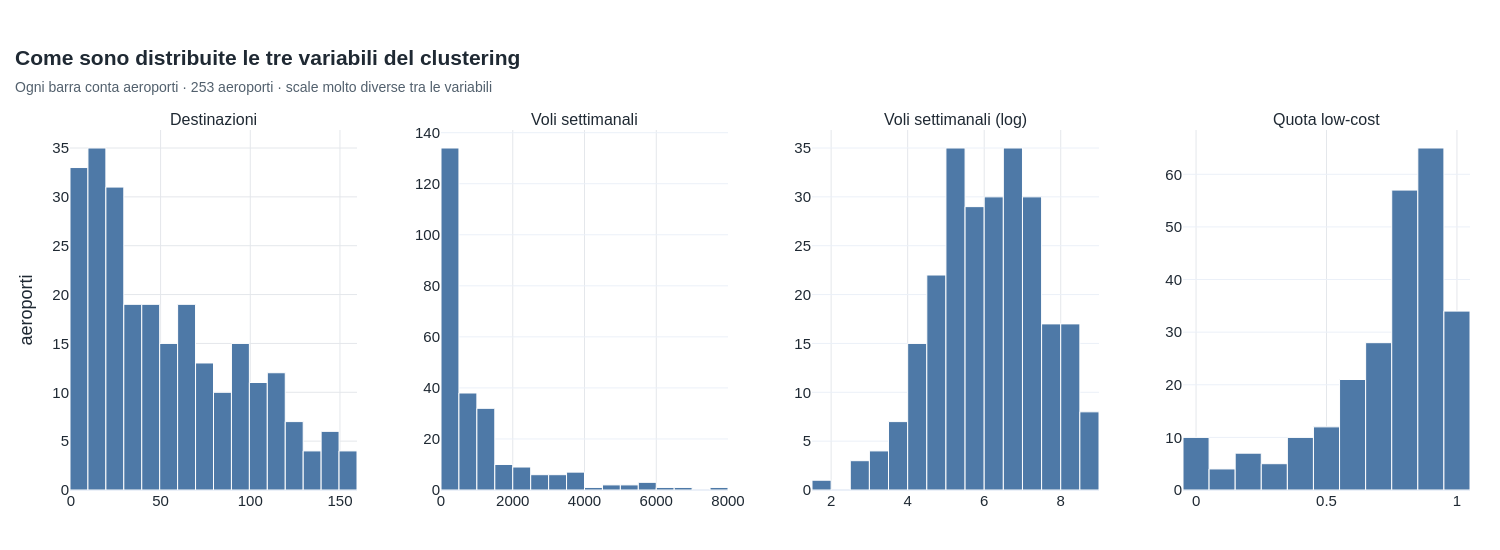

Asimmetria (skewness): {'destinazioni': 0.67, 'voli_sett': 2.31} | dopo il log, voli: -0.19


In [24]:
fig = make_subplots(rows=1, cols=4, subplot_titles=("Destinazioni", "Voli settimanali", "Voli settimanali (log)", "Quota low-cost"), horizontal_spacing=0.06)
for j, (x, nb_) in enumerate([(stats.destinazioni, 30), (stats.voli_sett, 30), (np.log1p(stats.voli_sett), 30), (stats.quota_lcc, 20)], start=1):
    fig.add_trace(go.Histogram(x=x, nbinsx=nb_, marker=dict(color="#4E79A7", line=dict(width=1, color="white"))), row=1, col=j)
base_layout(fig, "Come sono distribuite le tre variabili del clustering", "Ogni barra conta aeroporti · 253 aeroporti · scale molto diverse tra le variabili")
fig.update_layout(showlegend=False, margin=dict(t=130))
fig.update_yaxes(gridcolor="#e4e7eb", title_text="aeroporti", col=1); fig.update_xaxes(gridcolor="#e4e7eb")
show(fig, "14_istogrammi_variabili", w=1500, h=550)
print("Asimmetria (skewness):", stats[["destinazioni", "voli_sett"]].skew().round(2).to_dict(), "| dopo il log, voli:", round(float(np.log1p(stats.voli_sett).skew()), 2))

### 7.1 Quanti cluster? Gomito e silhouette

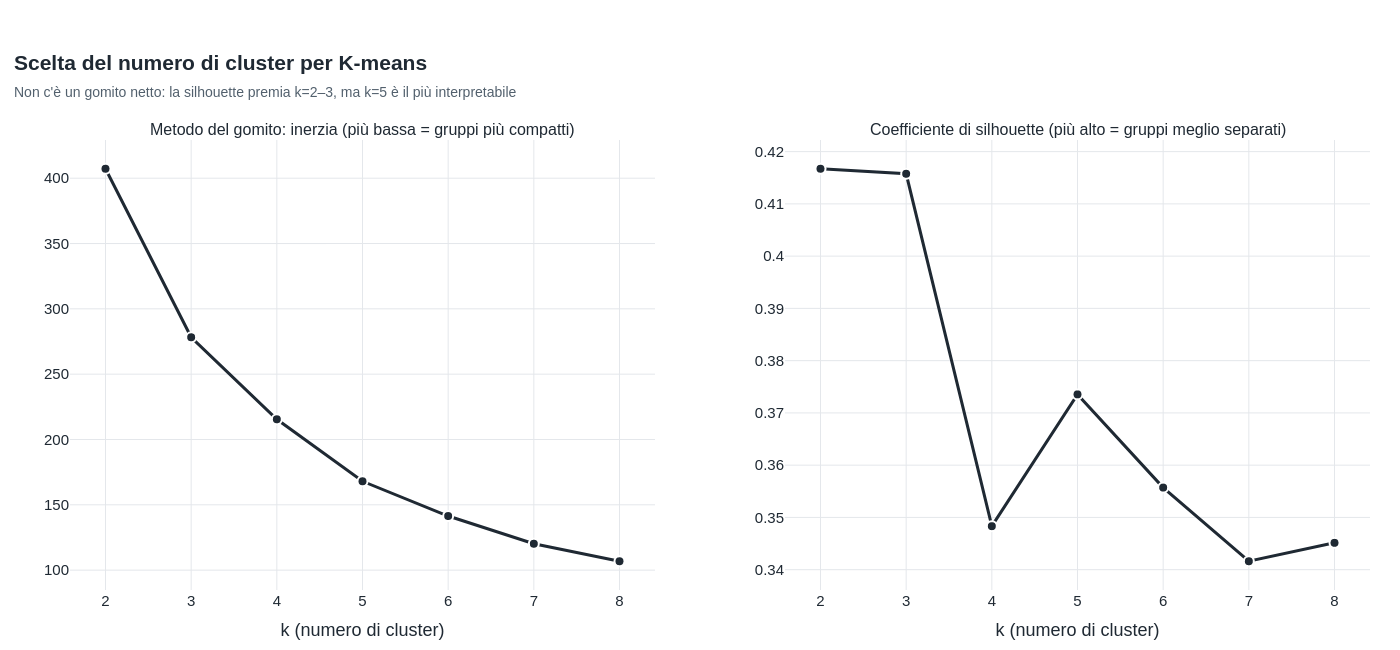

k,2,3,4,5,6,7,8
inerzia,407.224,278.246,215.471,168.019,141.425,120.205,106.811
silhouette,0.417,0.416,0.348,0.374,0.356,0.342,0.345


In [25]:
res = []
for k in range(2, 9):
    m = KMeans(n_clusters=k, n_init=50, random_state=0).fit(Z)
    res.append((k, m.inertia_, silhouette_score(Z, m.labels_)))
res = pd.DataFrame(res, columns=["k", "inerzia", "silhouette"]).set_index("k")

fig = make_subplots(rows=1, cols=2, subplot_titles=("Metodo del gomito: inerzia (più bassa = gruppi più compatti)", "Coefficiente di silhouette (più alto = gruppi meglio separati)"))
for j, col in enumerate(["inerzia", "silhouette"], start=1):
    fig.add_trace(go.Scatter(x=res.index, y=res[col], mode="lines+markers", line=dict(color=INK, width=3),
                             marker=dict(size=10, line=dict(width=2, color="white"))), row=1, col=j)
base_layout(fig, "Scelta del numero di cluster per K-means", "Non c'è un gomito netto: la silhouette premia k=2–3, ma k=5 è il più interpretabile")
fig.update_layout(showlegend=False, margin=dict(t=140))
fig.update_xaxes(title="k (numero di cluster)", dtick=1, gridcolor="#e4e7eb"); fig.update_yaxes(gridcolor="#e4e7eb")
show(fig, "10_scelta_k", w=1400, h=650)
res.round(3).T

**Lettura.** Non c'è un gomito netto (l'inerzia scende in modo regolare) e la silhouette è massima per k=2–3 (0,42), con un picco locale a k=5 (0,37). Valori sotto 0,5 indicano che i gruppi **non sono nettamente separati**: gli aeroporti formano più un continuum che gruppi distinti. Scegliamo **k=5** perché è il primo che separa gli hub tradizionali dai grandi scali low-cost: con k=3 e k=4 questa distinzione non emerge (si ottengono solo gruppi per dimensione).

### 7.2 K-means con k = 5: i profili dei gruppi

In [26]:
K = 5
km = KMeans(n_clusters=K, n_init=50, random_state=0).fit(Z)
stats["cluster_id"] = km.labels_

prof = stats.groupby("cluster_id").agg(aeroporti=("citta", "size"), destinazioni=("destinazioni", "mean"),
                                       voli_sett=("voli_sett", "mean"), quota_lcc=("quota_lcc", "mean"))

def name_cluster(r):
    """Nome del cluster in base al suo profilo medio (regole leggibili, non scelte a mano per ogni id)."""
    if r.quota_lcc < 0.5:
        return "Hub tradizionali" if r.destinazioni > 60 else "Piccoli scali (poche low-cost)"
    if r.destinazioni >= 100: return "Grandi scali a prevalenza low-cost"
    if r.destinazioni >= 40: return "Scali medi low-cost"
    return "Scali regionali low-cost"

prof["nome"] = prof.apply(name_cluster, axis=1)
stats["cluster"] = stats.cluster_id.map(prof.nome)
esempi = stats.sort_values("voli_sett", ascending=False).groupby("cluster").apply(lambda g: ", ".join(g.index[:6]), include_groups=False)
tab = prof.set_index("nome").join(esempi.rename("esempi (per voli)")).sort_values("destinazioni", ascending=False)
tab.round({"destinazioni": 0, "voli_sett": 0, "quota_lcc": 2})

,aeroporti,destinazioni,voli_sett,quota_lcc,esempi (per voli)
nome,,,,,
Grandi scali a prevalenza low-cost,50,114.0,2661.0,0.86,"AMS, BCN, MAD, FCO, CPH, DUB"
Hub tradizionali,11,112.0,3791.0,0.26,"FRA, IST, LHR, CDG, MUC, ZRH"
Scali medi low-cost,71,60.0,797.0,0.82,"LIN, BLQ, BGO, TFN, VCE, CTA"
Scali regionali low-cost,90,22.0,193.0,0.81,"LED, COV, SPC, CIA, TOS, TRF"
Piccoli scali (poche low-cost),31,12.0,225.0,0.23,"LCY, AER, SVO, TLL, BHD, ABZ"


### 7.3 I cluster sullo scatter e sulla mappa

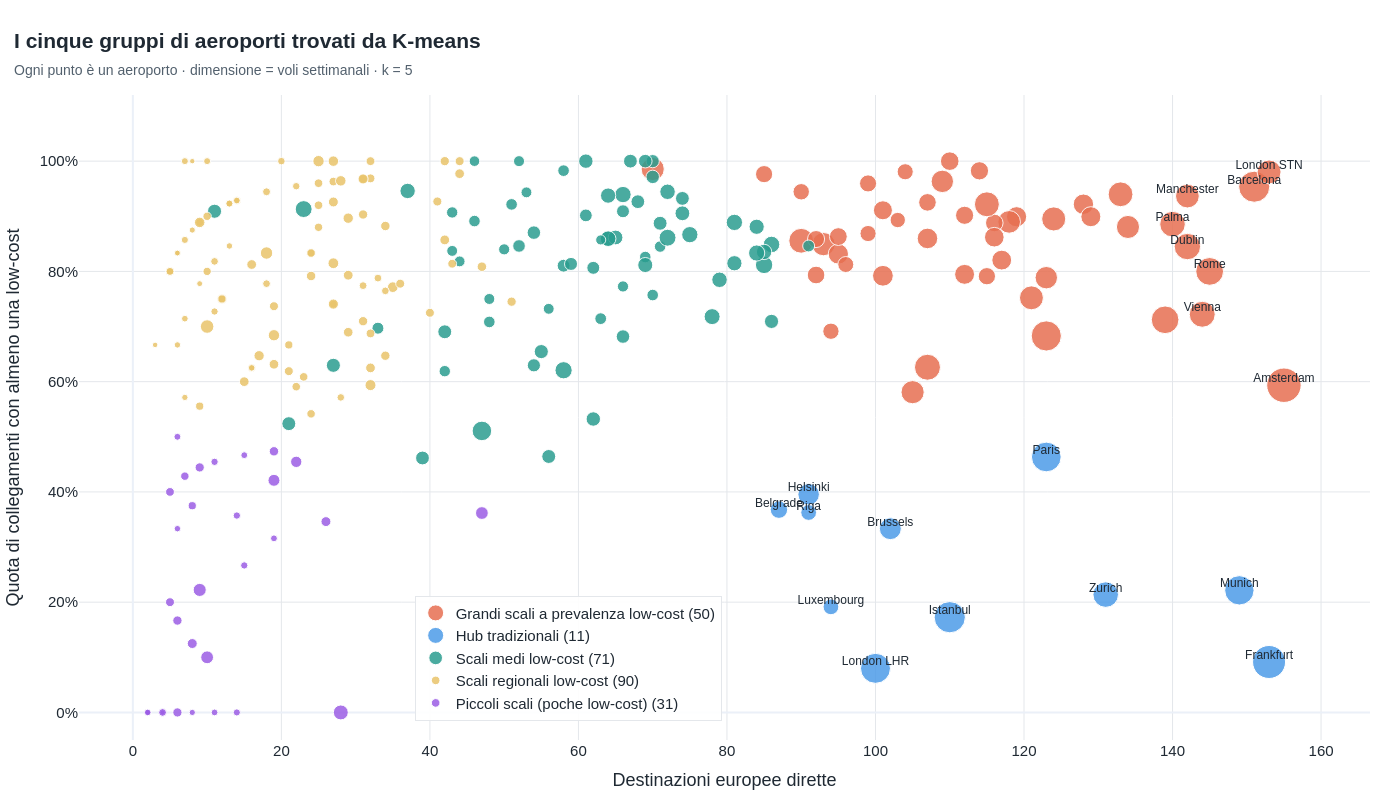

In [27]:
CL_COL = {"Hub tradizionali": "#4C9BE8", "Grandi scali a prevalenza low-cost": "#E76F51", "Scali medi low-cost": "#2A9D8F",
          "Scali regionali low-cost": "#E9C46A", "Piccoli scali (poche low-cost)": "#9B5DE5"}
ordine = tab.index.tolist()

fig = go.Figure()
for nome in ordine:
    g = stats[stats.cluster == nome]
    fig.add_trace(go.Scatter(x=g.destinazioni, y=g.quota_lcc, mode="markers", name=f"{nome} ({len(g)})",
                             marker=dict(size=np.sqrt(g.voli_sett) * 0.35 + 4, color=CL_COL[nome], line=dict(width=1, color="white"), opacity=0.85),
                             text=g.citta + " (" + g.index + ")", hovertemplate="%{text}<br>%{x} destinazioni<br>%{y:.0%} rotte con low-cost<extra></extra>"))
lab = stats[stats.cluster.isin(["Hub tradizionali"]) | (stats.destinazioni >= 140)]
fig.add_trace(go.Scatter(x=lab.destinazioni, y=lab.quota_lcc, mode="text", text=labels(lab), textposition="top center", textfont=dict(size=12), showlegend=False, hoverinfo="skip"))
base_layout(fig, "I cinque gruppi di aeroporti trovati da K-means", "Ogni punto è un aeroporto · dimensione = voli settimanali · k = 5")
fig.update_layout(legend=dict(orientation="v", x=0.26, y=0.03, xanchor="left", yanchor="bottom", bgcolor="rgba(255,255,255,0.92)", bordercolor="#e4e7eb", borderwidth=1))
fig.update_xaxes(title="Destinazioni europee dirette", gridcolor="#e4e7eb"); fig.update_yaxes(title="Quota di collegamenti con almeno una low-cost", tickformat=".0%", range=[-0.05, 1.12], gridcolor="#e4e7eb")
show(fig, "11_cluster_scatter", w=1400, h=800)

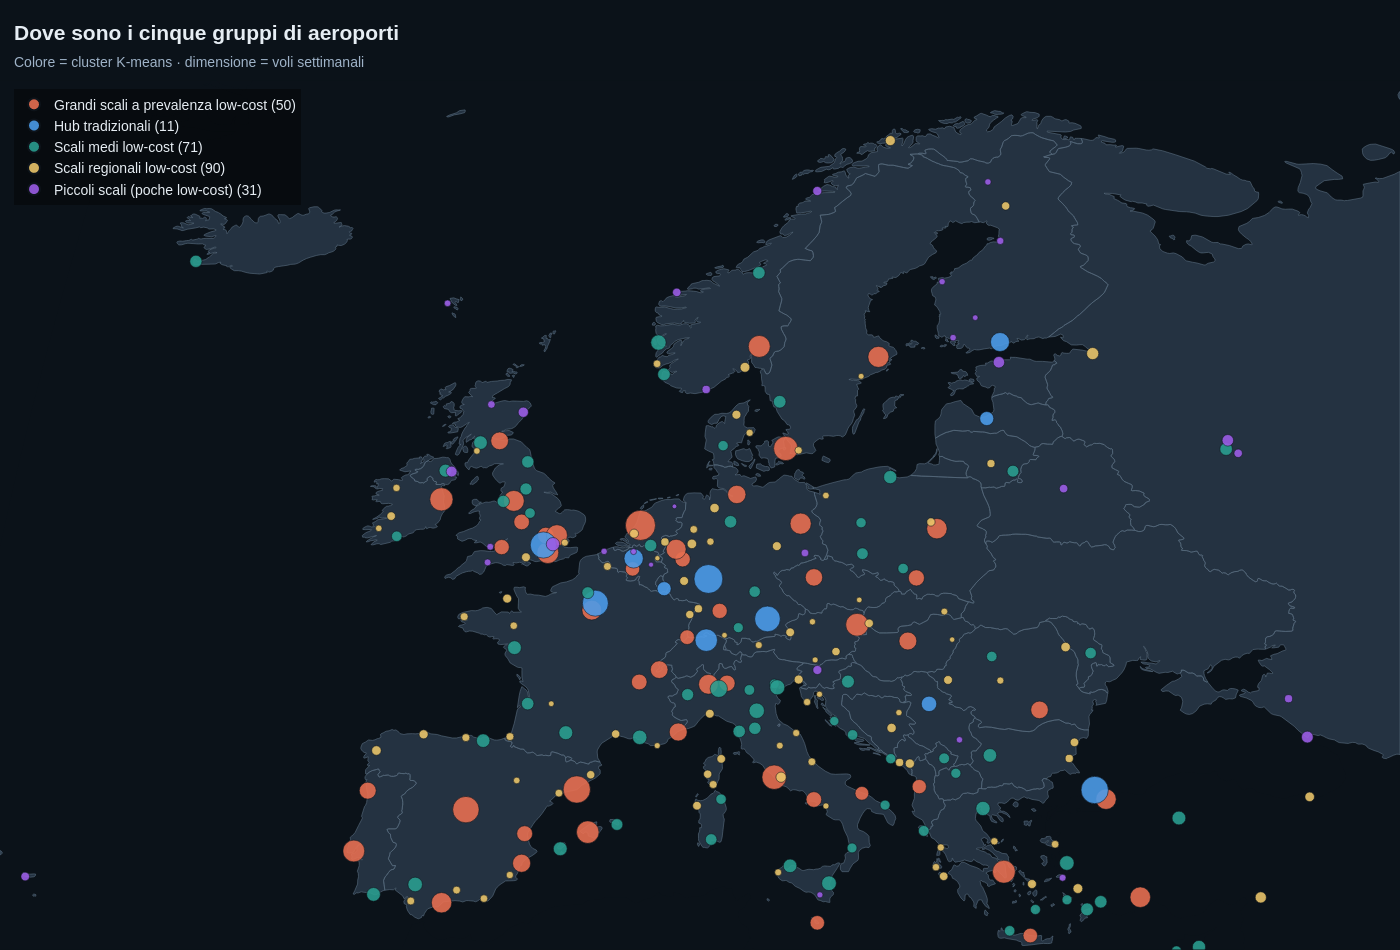

In [28]:
fig = go.Figure()
for nome in ordine:
    g = stats[stats.cluster == nome]
    fig.add_trace(go.Scattergeo(lat=g.lat, lon=g.lon, mode="markers", name=f"{nome} ({len(g)})",
                                marker=dict(size=np.sqrt(g.voli_sett) * 0.3 + 4, color=CL_COL[nome], line=dict(width=0.6, color="#0e151c"), opacity=0.9),
                                text=g.citta + " (" + g.index + ")", hoverinfo="text"))
fig.update_geos(**GEO)
fig.update_layout(template="plotly_dark", paper_bgcolor="#0b1219", font=dict(family="Arial", color="#e6edf3", size=15),
                  title=dict(text="<b>Dove sono i cinque gruppi di aeroporti</b><br><span style='font-size:14px;color:#9fb3c8'>Colore = cluster K-means · dimensione = voli settimanali</span>", x=0.01),
                  margin=dict(l=0, r=0, t=80, b=0), legend=dict(orientation="v", x=0.01, y=0.99, bgcolor="rgba(0,0,0,0.4)", font=dict(size=14), itemsizing="constant"))
show(fig, "12_cluster_mappa", w=1400, h=950)

**Cosa emerge.** K-means separa due gruppi di grandi scali di dimensione quasi identica (circa 112–114 destinazioni) ma con profilo opposto:
- **11 hub tradizionali** (in media 26% di collegamenti con low-cost): Francoforte, Istanbul, Heathrow, Parigi CDG, Monaco, Zurigo, Bruxelles, Helsinki, Belgrado, Riga, Lussemburgo.
- **50 grandi scali a prevalenza low-cost** (86%): Amsterdam, Barcellona, Madrid, Roma, Copenaghen, Dublino, Atene, Vienna, Palma, Stansted, Manchester e altri.

L'ipotesi dei "due modelli di hub" fatta a occhio è quindi **in gran parte ritrovata dai dati**, e la separazione è guidata dalla quota low-cost più che dalla dimensione. Sotto ci sono **71 scali medi low-cost**, **90 scali regionali low-cost** (in media 22 destinazioni, 81% low-cost) e **31 piccoli scali con poche low-cost**: aeroporti cittadini (London City, Belfast City) o legati a compagnie di bandiera (Mosca Sheremetyevo e Domodedovo, Soči).

**Casi di confine.** Amsterdam (59% di collegamenti con low-cost) e Varsavia (58%) stanno ora tra i grandi scali low-cost. Nella prima versione dell'analisi, prima di correggere l'errore di classificazione di *KM Malta Airlines* (36 collegamenti riclassificati), erano nel gruppo degli hub tradizionali: basta uno spostamento minimo dei dati per cambiare lato a un aeroporto vicino al confine. È un'altra prova che il confine è sfumato.

### 7.4 Confronto con mean-shift
Mean-shift non richiede k, ma ha un parametro equivalente: la **larghezza di banda** (quanto è ampia la finestra con cui cerca i "picchi" di densità). La stimiamo dai dati con diversi *quantili* e vediamo quanti cluster trova. Misuriamo l'accordo con K-means con l'**Adjusted Rand Index** (1 = partizioni identiche, 0 = accordo casuale).

In [29]:
rows = []
for q in [0.05, 0.1, 0.15, 0.2, 0.3]:
    bw = estimate_bandwidth(Z, quantile=q, random_state=0)
    ms = MeanShift(bandwidth=bw, bin_seeding=True).fit(Z)
    rows.append(dict(quantile=q, larghezza_banda=round(bw, 2), cluster_trovati=len(set(ms.labels_)),
                     dimensioni=sorted(np.bincount(ms.labels_), reverse=True), ARI_vs_Kmeans5=round(adjusted_rand_score(km.labels_, ms.labels_), 2)))
ms_tab = pd.DataFrame(rows).set_index("quantile")
ms_tab

,larghezza_banda,cluster_trovati,dimensioni,ARI_vs_Kmeans5
quantile,,,,
0.05,0.64,18,"[66, 51, 39, 17, 16, 13, 8, 7, 6, 6, 5, 5, 4, ...",0.54
0.10,0.87,5,"[107, 89, 27, 24, 6]",0.62
0.15,1.04,5,"[125, 80, 21, 16, 11]",0.53
0.20,1.20,2,"[199, 54]",0.23
0.30,1.48,2,"[214, 39]",0.15


In [30]:
# Stabilità di K-means: 20 inizializzazioni casuali (una sola partenza ciascuna) confrontate con la soluzione di riferimento
aris = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=1, random_state=sd).fit(Z).labels_) for sd in range(20)]
print(f"Stabilità K-means (k={K}): ARI medio = {np.mean(aris):.2f}, minimo = {np.min(aris):.2f} su 20 inizializzazioni")

MS_Q = 0.1
bw = estimate_bandwidth(Z, quantile=MS_Q, random_state=0)
ms = MeanShift(bandwidth=bw, bin_seeding=True).fit(Z)
stats["cluster_ms"] = ms.labels_
print(f"Mean-shift (quantile={MS_Q}): {len(set(ms.labels_))} cluster, ARI con K-means = {adjusted_rand_score(km.labels_, ms.labels_):.2f}")
pd.crosstab(stats.cluster, stats.cluster_ms, rownames=["K-means"], colnames=["mean-shift"]).loc[ordine]

Stabilità K-means (k=5): ARI medio = 0.71, minimo = 0.43 su 20 inizializzazioni


Mean-shift (quantile=0.1): 5 cluster, ARI con K-means = 0.62


mean-shift,0,1,2,3,4
K-means,,,,,
Grandi scali a prevalenza low-cost,0,32,0,0,18
Hub tradizionali,0,0,0,6,5
Scali medi low-cost,13,57,0,0,1
Scali regionali low-cost,90,0,0,0,0
Piccoli scali (poche low-cost),4,0,27,0,0


**Confronto con mean-shift.** Il numero di cluster di mean-shift **dipende dalla larghezza di banda**: 18 gruppi con quantile 0,05, 5 gruppi con 0,10 e 0,15, 2 gruppi con 0,20–0,30 (ARI con K-means: 0,62 e 0,53 nei casi a 5 cluster, 0,15–0,23 con 2 cluster). Quindi k=5 è plausibile, perché mean-shift a banda fine ne trova lo stesso numero, ma **non è un numero netto**.

La tabella mostra cosa è robusto e cosa no:
- **Robusto:** tutti e 90 gli scali regionali low-cost finiscono nello stesso cluster mean-shift, e 27 dei 31 piccoli scali con poche low-cost formano un gruppo a sé.
- **Fragile:** la separazione degli hub. Mean-shift isola solo 6 degli 11 hub tradizionali e mette gli altri 5 insieme a 18 grandi scali low-cost.

Anche K-means ha una stabilità moderata: l'ARI medio tra inizializzazioni singole è 0,71 (minimo 0,43); per questo usiamo `n_init=50`, che tiene la soluzione migliore. **In sintesi:** la struttura per dimensione e la presenza di scali con poche low-cost sono robuste; la distinzione fine tra hub tradizionali e grandi scali low-cost è interpretabile ma dipende dall'algoritmo e dal confine sfumato.

### 7.5 Quali variabili guidano i cluster?

La prof chiede di capire **quali variabili contano**. K-means non lo dice direttamente, quindi lo misuriamo in tre modi:

1. **Centroidi** (heatmap): il profilo medio di ogni cluster, in unità standardizzate (0 = media di tutti gli aeroporti, +1 = una deviazione standard sopra).
2. **Varianza spiegata** (η²): quanta parte della variabilità di una variabile è spiegata dall'appartenenza al cluster. Vale 0 se i cluster non la distinguono, 1 se la separano del tutto.
3. **Ablazione**: rifacciamo K-means togliendo una variabile alla volta e misuriamo con l'Adjusted Rand Index quanto la partizione cambia rispetto a quella con tutte e tre. ARI vicino a 1 = la variabile tolta non serviva; ARI basso = la variabile era importante.

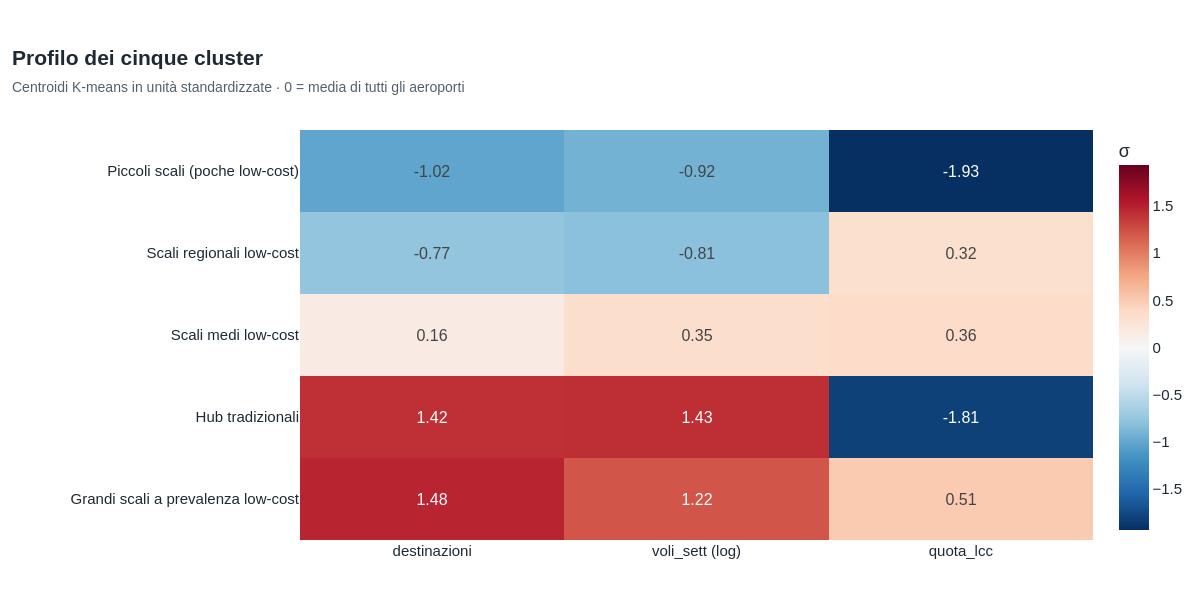

,varianza spiegata (η²),ARI senza la variabile
destinazioni,0.86,0.42
voli_sett (log),0.75,0.39
quota_lcc,0.72,0.53


In [31]:
def eta2(z, lab):
    """Quota di varianza di z spiegata dai gruppi `lab` (0 = nessuna, 1 = tutta)."""
    z, lab = np.asarray(z, float), np.asarray(lab)
    return sum((lab == c).sum() * (z[lab == c].mean() - z.mean()) ** 2 for c in np.unique(lab)) / ((z - z.mean()) ** 2).sum()

nomi = list(feat.columns)
ordine_cl = list(tab.index)                                    # stesso ordine dei cluster usato sopra

# (1) centroidi in unità standardizzate
cent = pd.DataFrame(km.cluster_centers_, columns=nomi).rename(index=prof.nome.to_dict()).loc[ordine_cl]
fig = go.Figure(go.Heatmap(z=cent.values, x=nomi, y=cent.index, colorscale="RdBu_r", zmid=0,
                           text=cent.round(2).values, texttemplate="%{text}", textfont=dict(size=16), colorbar=dict(title="σ")))
base_layout(fig, "Profilo dei cinque cluster", "Centroidi K-means in unità standardizzate · 0 = media di tutti gli aeroporti")
fig.update_layout(margin=dict(l=300, t=130))
show(fig, "13_centroidi_cluster", w=1200, h=600)

# (2) varianza spiegata e (3) ablazione
eta = {n: eta2(Z[:, j], km.labels_) for j, n in enumerate(nomi)}
abl = {n: adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=50, random_state=0).fit_predict(np.delete(Z, j, axis=1)))
       for j, n in enumerate(nomi)}
imp = pd.DataFrame({"varianza spiegata (η²)": eta, "ARI senza la variabile": abl}).round(2)
imp

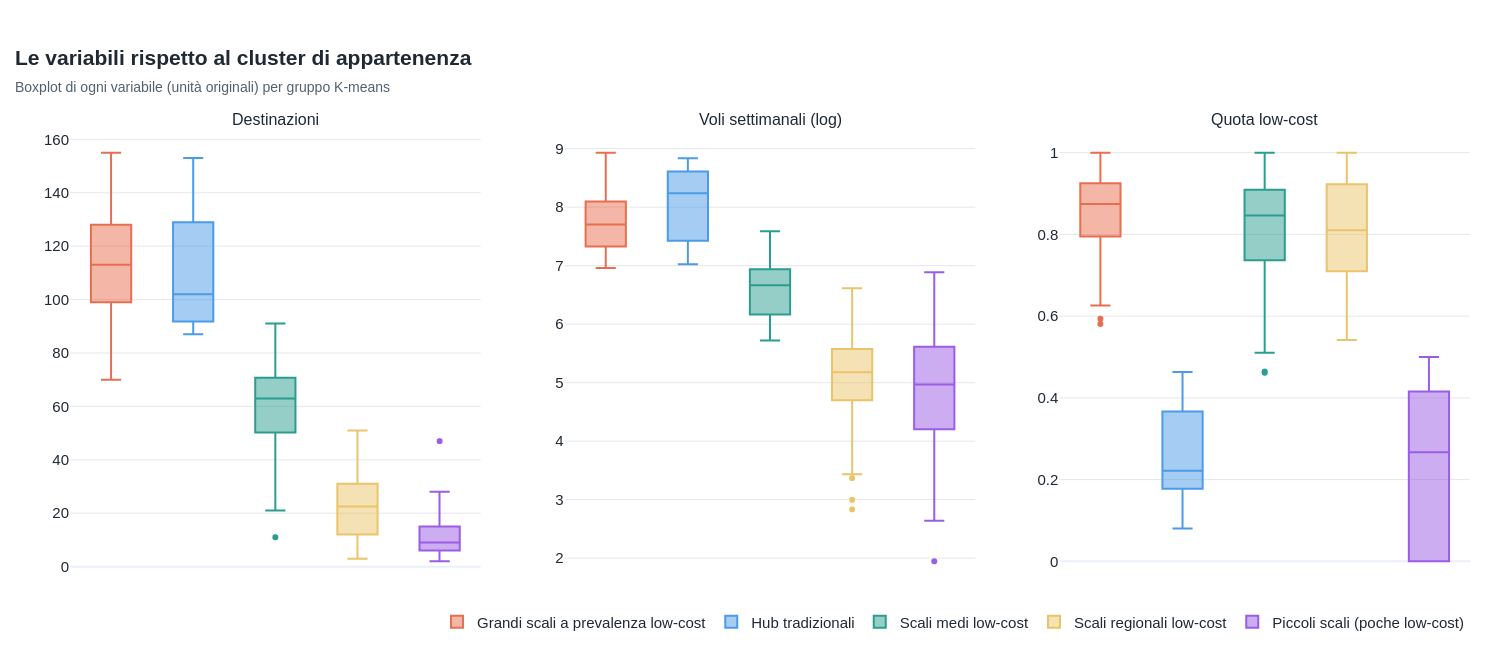

In [32]:
fig = make_subplots(rows=1, cols=3, subplot_titles=("Destinazioni", "Voli settimanali (log)", "Quota low-cost"), horizontal_spacing=0.06)
for j, col in enumerate(feat.columns, start=1):
    for nome in ordine_cl:
        fig.add_trace(go.Box(y=feat.loc[stats.cluster == nome, col], name=nome, marker_color=CL_COL[nome], boxpoints="outliers", showlegend=(j == 1)), row=1, col=j)
base_layout(fig, "Le variabili rispetto al cluster di appartenenza", "Boxplot di ogni variabile (unità originali) per gruppo K-means")
fig.update_layout(margin=dict(t=130), legend=dict(orientation="h", y=-0.12))
fig.update_yaxes(gridcolor="#e4e7eb"); fig.update_xaxes(showticklabels=False)
show(fig, "15_variabili_per_cluster", w=1500, h=650)

In [33]:
# Cosa succede senza la quota low-cost? I due tipi di grandi scali si separano ancora?
lab_senza_lcc = KMeans(n_clusters=K, n_init=50, random_state=0).fit_predict(np.delete(Z, nomi.index("quota_lcc"), axis=1))
pd.crosstab(stats.cluster, lab_senza_lcc, rownames=["cluster completo"], colnames=["K-means senza quota_lcc"]).loc[ordine_cl]

K-means senza quota_lcc,0,1,2,3,4
cluster completo,,,,,
Grandi scali a prevalenza low-cost,0,0,21,0,29
Hub tradizionali,0,0,6,0,5
Scali medi low-cost,57,0,0,1,13
Scali regionali low-cost,0,24,0,66,0
Piccoli scali (poche low-cost),2,15,0,14,0


**Lettura.** Le due variabili di dimensione (destinazioni e voli settimanali) sono fortemente correlate (r = 0,88), quindi la dimensione entra di fatto due volte nel calcolo delle distanze e pesa più della quota low-cost. Le η² dicono che tutte e tre le variabili sono ben separate dai cluster: 0,86 per le destinazioni, 0,75 per i voli, 0,72 per la quota low-cost. Togliendo una variabile alla volta, l'ARI con la partizione completa scende a 0,42 (senza destinazioni), 0,39 (senza voli) e 0,53 (senza quota low-cost): per la partizione complessiva la quota low-cost è la variabile meno decisiva, anche se le differenze sono modeste e K-means non è del tutto stabile (ARI medio tra inizializzazioni singole 0,71).

La quota low-cost è però **indispensabile per la distinzione che ci interessa**. Nella heatmap i due gruppi di grandi scali hanno la stessa dimensione (circa +1,5 σ per le destinazioni) ma quota low-cost opposta (−1,8 σ per gli hub tradizionali, +0,5 σ per i grandi scali low-cost). Senza quella variabile (tabella sotto) i due tipi di grandi scali finiscono mescolati negli stessi gruppi. Attenzione: η² è calcolato sugli stessi dati usati per formare i cluster, quindi è descrittivo, non un test di significatività.

### 7.6 La standardizzazione cambia il risultato?

Le tre variabili hanno scale molto diverse (le destinazioni arrivano a oltre 150, i voli in scala logaritmica a circa 9, la quota low-cost va da 0 a 1). K-means usa la distanza euclidea, quindi **senza standardizzare pesa di più la variabile con la scala maggiore**. Per valutare la scelta rifacciamo K-means sulle variabili grezze con lo stesso k e lo confrontiamo con la versione standardizzata, con tre misure: ARI tra le due partizioni, silhouette di entrambe calcolata nello **stesso spazio standardizzato** (altrimenti i due valori non sono confrontabili) e η² di ogni variabile.

In [34]:
X_raw = feat.values
km_raw = KMeans(n_clusters=K, n_init=50, random_state=0).fit(X_raw)

print(f"ARI tra K-means standardizzato e non standardizzato: {adjusted_rand_score(km.labels_, km_raw.labels_):.2f}")
print(f"Silhouette nello spazio standardizzato: standardizzato = {silhouette_score(Z, km.labels_):.2f}, "
      f"non standardizzato = {silhouette_score(Z, km_raw.labels_):.2f}")
print("Peso di ogni variabile nella distanza senza standardizzare (quota di varianza totale):")
print((feat.var() / feat.var().sum()).round(3).to_string())

conf = pd.DataFrame({"η² con standardizzazione": [eta2(Z[:, j], km.labels_) for j in range(len(nomi))],
                     "η² senza standardizzazione": [eta2(X_raw[:, j], km_raw.labels_) for j in range(len(nomi))]}, index=nomi).round(2)
prof_raw = feat.groupby(km_raw.labels_).mean().round(2)
prof_raw.insert(0, "aeroporti", np.bincount(km_raw.labels_))
display(conf)
display(prof_raw.sort_values("destinazioni", ascending=False))

ARI tra K-means standardizzato e non standardizzato: 0.39
Silhouette nello spazio standardizzato: standardizzato = 0.37, non standardizzato = 0.14
Peso di ogni variabile nella distanza senza standardizzare (quota di varianza totale):
destinazioni       0.999
voli_sett (log)    0.001
quota_lcc          0.000


,η² con standardizzazione,η² senza standardizzazione
destinazioni,0.86,0.96
voli_sett (log),0.75,0.74
quota_lcc,0.72,0.15


,aeroporti,destinazioni,voli_sett (log),quota_lcc
2,29,131.45,8.10,0.77
3,40,95.90,7.42,0.75
1,47,63.79,6.58,0.84
4,62,33.82,5.69,0.78
0,75,11.45,4.76,0.58


**Lettura.** Senza standardizzazione le destinazioni pesano il 99,9% della varianza totale (i voli in scala logaritmica lo 0,1%, la quota low-cost meno dello 0,05%): K-means diventa di fatto un raggruppamento per dimensione. Lo mostra la η² della quota low-cost, che scende da 0,72 a 0,15, e la tabella dei profili: i cinque gruppi si ordinano per numero di destinazioni e hanno tutti una quota low-cost tra 0,58 e 0,84, quindi non compaiono né gli hub tradizionali (26% low-cost) né i piccoli scali con poche low-cost (23%). La partizione cambia molto (ARI 0,39 rispetto alla versione standardizzata) e la silhouette, misurata nello stesso spazio standardizzato, scende da 0,37 a 0,14. La standardizzazione è quindi necessaria per rispondere alla nostra domanda di ricerca.

### 7.7 Il clustering come modello della percezione

Il corso studia gli algoritmi come **modelli semplificati di ciò che fa la percezione umana**. Davanti a uno scatter come quello del paragrafo 7.3 l'occhio raggruppa i punti per **vicinanza** e per **somiglianza** (due principi classici della psicologia della Gestalt). Il clustering prova a rendere esplicito questo raggruppamento:

- **K-means** fa il raggruppamento per somiglianza. La distanza tra aeroporti, calcolata sulle variabili standardizzate, fa da "somiglianza percepita"; il centroide è il *prototipo* del gruppo, cioè l'aeroporto "medio" a cui gli altri assomigliano.
- **Mean-shift** cerca i picchi di densità, come i "grumi" che l'occhio nota. La **larghezza di banda** è la scala a cui si guarda, come lo zoom: a scala fine trova 18 gruppi, a scala larga 2. Anche la percezione umana cambia raggruppamento al cambiare della scala.
- **Differenze con l'occhio umano.** L'algoritmo usa tre variabili (noi, sullo scatter, ne vediamo due più la dimensione dei punti) e assegna a ogni aeroporto un solo gruppo con confine netto. Noi vediamo invece un continuum, ed è coerente con la silhouette di 0,37.

Si tratta di un'analogia: il confronto non prova che l'occhio faccia davvero K-means, ma permette di discutere cosa il modello cattura del raggruppamento percettivo e cosa no.

## 8. Sintesi numerica

In [35]:
import json
w = edges.groupby("tipo").voli_sett.sum()
summary = dict(
    n_airports=len(stats), n_countries=int(stats.paese.nunique()),
    n_routes_directed=len(df), n_edges=len(edges), voli_sett_tot=int(edges.voli_sett.sum()),
    raw_rows=len(raw),
    quota_tipo_rotte={k: round(v, 4) for k, v in df.tipo.value_counts(normalize=True).items()},
    quota_rotte_con_lcc=round(float(df.has_lcc.mean()), 4),
    quota_voli_con_lcc=round(float(edges.loc[edges.has_lcc, "voli_sett"].sum() / edges.voli_sett.sum()), 4),
    top_hubs=[dict(citta=r.citta, iata=i, paese=r.paese, destinazioni=int(r.destinazioni), voli_sett=int(r.voli_sett), quota_lcc=round(r.quota_lcc, 3))
              for i, r in stats.nlargest(10, "destinazioni").iterrows()],
    top_carriers=[dict(nome=n, rotte=int(r.rotte), lcc=bool(r.low_cost)) for n, r in top_carriers.head(10).iterrows()],
    top5_carriers_share=round(float(share_top5), 3),
    nuove_rotte={k: {t: int(v) for t, v in row.items()} for k, row in coh.iterrows()},
    quota_lcc_anno={k: round(float(v), 3) for k, v in quota.items()},
    categoria_rete={k: round(float(v), 3) for k, v in edges.categoria.value_counts(normalize=True).items()},
    categoria_anno={k: {c: round(float(v), 3) for c, v in row.items()} for k, row in cat_pct.iterrows()},
    quota_domestici={k: round(float(v), 3) for k, v in dom.items()},
    prezzo_mediano={k: float(v) for k, v in med.items()},
    top_edges=[dict(a=r.a, b=r.b, voli=int(r.voli_sett), tipo=r.tipo) for r in edges.nlargest(5, "voli_sett").itertuples()],
    data_known_share=round(len(ed_all) / len(edges), 3),
    data_estrazione=str(EXTRACTION_DATE.date()), n_collegamenti_annunciati=int(len(ann)), n_colonne=int(raw.shape[1]),
    clustering=dict(k=K, silhouette={int(k): round(float(v), 3) for k, v in res.silhouette.items()},
                    profili={n: dict(aeroporti=int(r.aeroporti), destinazioni=round(float(r.destinazioni)), voli_sett=round(float(r.voli_sett)),
                                     quota_lcc=round(float(r.quota_lcc), 2), esempi=r["esempi (per voli)"]) for n, r in tab.iterrows()},
                    meanshift={str(q): dict(cluster=int(r.cluster_trovati), ari=float(r.ARI_vs_Kmeans5)) for q, r in ms_tab.iterrows()},
                    stabilita_ari_medio=round(float(np.mean(aris)), 2)),
)
(OUT / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=1), encoding="utf-8")
summary

{'n_airports': 253,
 'n_countries': 42,
 'n_routes_directed': 13499,
 'n_edges': 6801,
 'voli_sett_tot': 127820,
 'raw_rows': 18111,
 'quota_tipo_rotte': {'Low-cost': 0.6122,
  'Tradizionale': 0.2291,
  'Mista': 0.1587},
 'quota_rotte_con_lcc': 0.7709,
 'quota_voli_con_lcc': 0.6733,
 'top_hubs': [{'citta': 'Amsterdam',
   'iata': 'AMS',
   'paese': 'Netherlands',
   'destinazioni': 155,
   'voli_sett': 7564,
   'quota_lcc': 0.594},
  {'citta': 'Frankfurt',
   'iata': 'FRA',
   'paese': 'Germany',
   'destinazioni': 153,
   'voli_sett': 6866,
   'quota_lcc': 0.092},
  {'citta': 'London',
   'iata': 'STN',
   'paese': 'United Kingdom',
   'destinazioni': 153,
   'voli_sett': 3239,
   'quota_lcc': 0.98},
  {'citta': 'Barcelona',
   'iata': 'BCN',
   'paese': 'Spain',
   'destinazioni': 151,
   'voli_sett': 5991,
   'quota_lcc': 0.954},
  {'citta': 'Munich',
   'iata': 'MUC',
   'paese': 'Germany',
   'destinazioni': 149,
   'voli_sett': 5245,
   'quota_lcc': 0.221},
  {'citta': 'Rome',
  

## 9. Conclusioni e limiti

**Conclusioni**
1. Il cielo europeo è una rete **densa, policentrica e dominata dalle low-cost per numero di rotte**: il 77% delle rotte ha almeno una low-cost e Ryanair da sola ne opera più di 4.400. Le dorsali a più alta frequenza (il 4% dei collegamenti, 31% dei voli) sono però quasi sempre miste o tradizionali: le puramente low-cost portano solo l'8% dei loro voli.
2. Esistono **due modelli di hub**: gli scali storici delle compagnie tradizionali (Francoforte, Heathrow, Monaco, Zurigo) e le grandi basi low-cost (Stansted, Barcellona, Manchester). Il **clustering K-means (k=5)** ritrova la distinzione nei dati: 11 hub tradizionali (26% low-cost) contro 50 grandi scali a prevalenza low-cost (86%), a parità di dimensione, con casi di confine come Amsterdam e Varsavia.
3. La connettività si è spostata verso i **collegamenti tra scali regionali**: oggi sono il 55% della rete e il 56–65% delle rotte aperte dal 2022 in poi.
4. Dopo il calo del 2021 la rete si è ripresa con circa 430–565 nuove rotte l'anno nel 2022–2024 e un mix low-cost stabile.
5. Il **turismo** pesa molto sulla geografia dei flussi (corridoi Nord → Sud, Spagna come nodo centrale) e una quota rilevante del traffico è domestico.

**Limiti dell'analisi**
- Il dataset è una **fotografia della programmazione di agosto 2025** (con rotte fino a ottobre 2026), ottenuta con scraping, ma validata sui dati Eurostat 2024 (Spearman 0,98 per aeroporto): non è una serie storica, l'evoluzione è ricostruita dalla data del primo volo e vede solo le rotte sopravvissute (*survivorship bias*); il picco 2018 è un artefatto della raccolta dati.
- Non ci sono dati sui **passeggeri**: il volume è approssimato con i voli settimanali.
- Per circa il 15% dei collegamenti la data di primo volo è sconosciuta.
- La classificazione low-cost è nostra (il flag del dataset è incoerente) e i confini tra low-cost, ibride e leisure sono sfumati.
- Il campo `price` è solo una stima non documentata (11% di zeri).
- **Copertura:** solo ~260 grandi aeroporti scelti dall'autore: i "regionali" sono scali medio-grandi e le destinazioni sono contate solo verso aeroporti del campione.
- **Sensibilità:** riclassificare 36 collegamenti (KM Malta Airlines) ha spostato Amsterdam e Varsavia di cluster: i risultati del clustering vanno letti come indicativi.
- La data di estrazione (11/8/2025) è quella dichiarata su Kaggle e coerente con i dati; con la lettura 8 novembre cambierebbero solo ~340 righe di rotte annunciate.

- Il clustering è sensibile al numero di cluster e all'algoritmo: silhouette 0,37 per k=5 e mean-shift che trova da 2 a 18 gruppi a seconda della larghezza di banda. I gruppi hanno confini sfumati.

**Sviluppi possibili:** integrare i dati Eurostat sui passeggeri per aeroporto, pesare i collegamenti per capacità (posti) e calcolare misure di centralità sul grafo.